In [1]:
import torch 
import tqdm
import networkx as nx
import pandas as pd
import os
import matplotlib.pyplot as plt

from agfn.gflownet import GFlowNet
from agfn.gym import MAG, LogReward
from agfn.policies import ForwardPolicy, BackwardPolicy
from agfn.hitl import find_next_query, posterior_update, get_response_from_oracle

HERE = os.path.dirname(os.getcwd())

def test_gflownet():
    num_nodes = 5
    # Create a MAG with 5 nodes
    mag = MAG(num_nodes, batch_size=1, log_reward=None)
    pf = ForwardPolicy(num_nodes=num_nodes, hidden_dim=128, num_layers=2)
    pb = BackwardPolicy()
    gfn = GFlowNet(pf, pb)
    gfn.sample(mag)
    return mag.adjacency_matrix

assert isinstance(test_gflownet(), torch.Tensor) 

def test_gflownet_set_posterior():
    num_nodes = 5
    # Create a MAG with 5 nodes
    mag = MAG(num_nodes, batch_size=1, log_reward=None)
    pf = ForwardPolicy(num_nodes=num_nodes, hidden_dim=128, num_layers=2)
    pb = BackwardPolicy()
    gfn = GFlowNet(pf, pb)

    num_edges = (num_nodes * (num_nodes - 1)) // 2
    posterior = torch.ones((num_edges, 4)) / 4
    gfn.set_posterior(posterior)
    gfn.sample(mag)
    return mag.adjacency_matrix

assert isinstance(test_gflownet_set_posterior(), torch.Tensor) 

In [2]:
num_nodes = 5
# Create a simple LogReward
true_mag, samples = MAG.generate_dag_with_bounded_degree(num_nodes, max_degree=2, num_samples=100)

In [3]:
log_reward = LogReward(samples)

## Train a GFlowNet on `log_reward`

In [4]:
pf = ForwardPolicy(num_nodes, hidden_dim=128, num_layers=2)
pb = BackwardPolicy()
gfn = GFlowNet(pf, pb)

log_reward.warmup(gfn, MAG(num_nodes, batch_size=128, log_reward=log_reward), num_batches=100)

In [5]:
opt = torch.optim.Adam([
    {"params": gfn.pf.parameters(), "lr": 1e-3},
    {"params": gfn.pb.parameters(), "lr": 1e-3},
    {"params": gfn.log_z, "lr": 1e-1},
], lr=1e-3)

pbar = tqdm.tqdm(range(int(5e1)), disable=False)
for epoch in pbar:
    initial_state = MAG(num_nodes, batch_size=128, log_reward=log_reward)
    opt.zero_grad()
    loss = gfn(initial_state)
    loss.backward()
    opt.step()
    pbar.set_postfix(loss=loss.item())

100%|██████████| 50/50 [00:01<00:00, 25.16it/s, loss=3.21]


## Human in the loop

In [5]:
def oracle(query):
    amag = nx.adjacency_matrix(true_mag)
    return get_response_from_oracle(query, adj=amag)

In [6]:
gfn.eval()
queries = list()
responses = list()

for _ in range(10):
    query = find_next_query(
        gfn, 
        log_reward, 
        queries=queries, 
        responses=responses, 
        pi=0.95,
        num_iterations=2
    )
    response = oracle(query)
    queries.append(query)
    responses.append(response.value)
    print(f"Query: {query}, Response: {response}")

Query: 9, Response: EdgeType.NO_RELATIONSHIP
Query: 2, Response: EdgeType.NO_RELATIONSHIP
Query: 0, Response: EdgeType.NO_RELATIONSHIP


KeyboardInterrupt: 

In [77]:
# Sample from the resulting posterior
num_edges = (num_nodes * (num_nodes - 1)) // 2
posterior_dist = posterior_update(responses, queries, num_edges, pi=0.95)

gfn.set_posterior(posterior_dist)

In [78]:
initial_state = MAG(num_nodes, batch_size=128, log_reward=log_reward)
mag = gfn.sample(initial_state)

## Training with (realistic) data

In [3]:
data = pd.read_csv(f'{HERE}/data/chain4_dat01.csv')
data = torch.tensor(data.values, dtype=torch.get_default_dtype())
num_nodes = data.shape[1]
num_edges = (num_nodes * (num_nodes - 1)) // 2

In [4]:
pf = ForwardPolicy(num_nodes, hidden_dim=128, num_layers=2)
pb = BackwardPolicy()
gfn = GFlowNet(pf, pb)

batch_size = 128

log_reward = LogReward(data)
log_reward.warmup(gfn, MAG(num_nodes, batch_size=batch_size, log_reward=log_reward), num_batches=100)

In [5]:
opt = torch.optim.Adam([
    {"params": gfn.pf.parameters(), "lr": 1e-3},
    {"params": gfn.pb.parameters(), "lr": 1e-3},
    {"params": gfn.log_z, "lr": 1e-1},
], lr=1e-3)

pbar = tqdm.tqdm(range(int(5e1)), disable=False)
for epoch in pbar:
    initial_state = MAG(num_nodes, batch_size=batch_size, log_reward=log_reward)
    opt.zero_grad()
    loss = gfn(initial_state)
    loss.backward()
    opt.step()
    pbar.set_postfix(loss=loss.item())

100%|██████████| 50/50 [00:02<00:00, 18.38it/s, loss=4.5] 


In [6]:
def get_oracle_feedback(query):
    # A -> B -> C -> D
    true_adj = torch.tensor(
        [
            [0, 1, 0, 0],
            [0, 0, 1, 0],
            [0, 0, 0, 1],
            [0, 0, 0, 0],
        ]
    )
    return get_response_from_oracle(query, adj=true_adj)  # The expert is an oracle

In [7]:
gfn.eval()
queries = list()
responses = list()

pi = 0.999

for _ in range(num_edges):
    query = find_next_query(
        gfn, 
        log_reward, 
        queries=queries, 
        responses=responses, 
        mask_queried_edges=True,
        pi=pi,
        num_iterations=2
    )
    response = get_oracle_feedback(query)
    queries.append(query)
    responses.append(response.value)
    print(f"Query: {query}, Response: {response}")

posterior_dist = posterior_update(responses, queries, num_edges, pi=pi)
gfn.set_posterior(posterior_dist)

Query: 1, Response: EdgeType.NO_RELATIONSHIP
Query: 5, Response: EdgeType.LEFT_CAUSES_RIGHT
Query: 3, Response: EdgeType.LEFT_CAUSES_RIGHT
Query: 2, Response: EdgeType.NO_RELATIONSHIP
Query: 0, Response: EdgeType.LEFT_CAUSES_RIGHT
Query: 4, Response: EdgeType.NO_RELATIONSHIP


In [8]:
gfn.pf.posterior

tensor([[0.0013, 0.9960, 0.0013, 0.0013],
        [0.9960, 0.0013, 0.0013, 0.0013],
        [0.9960, 0.0013, 0.0013, 0.0013],
        [0.0013, 0.9960, 0.0013, 0.0013],
        [0.9960, 0.0013, 0.0013, 0.0013],
        [0.0013, 0.9960, 0.0013, 0.0013]])

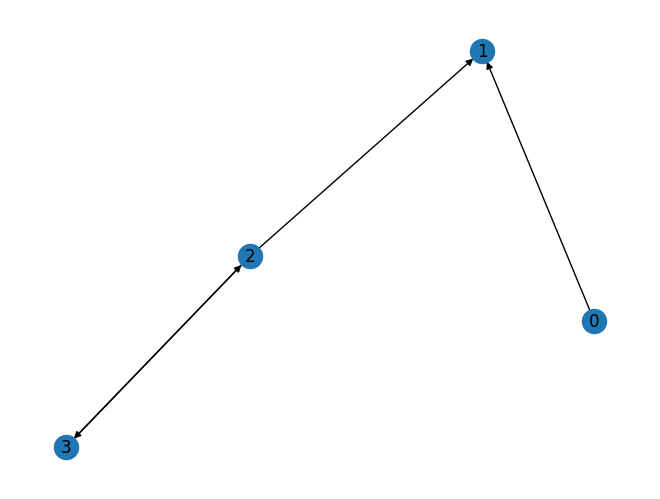

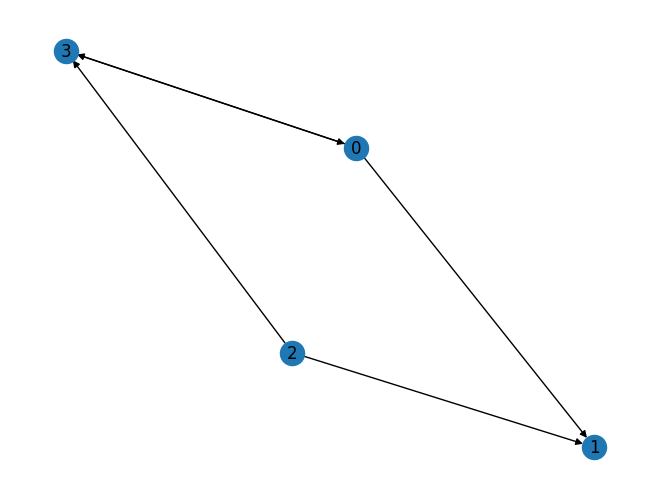

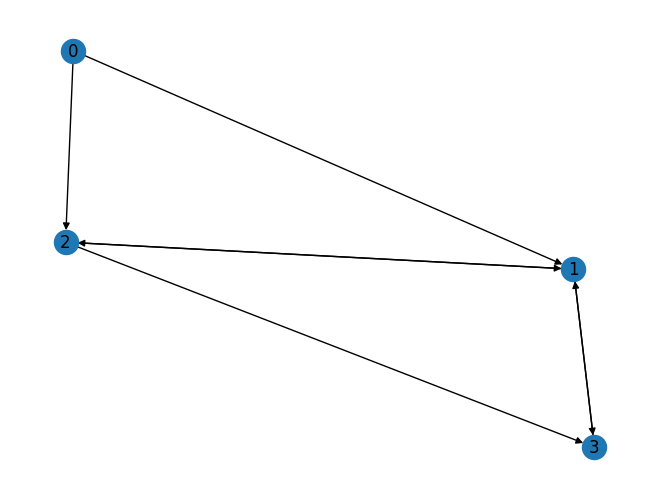

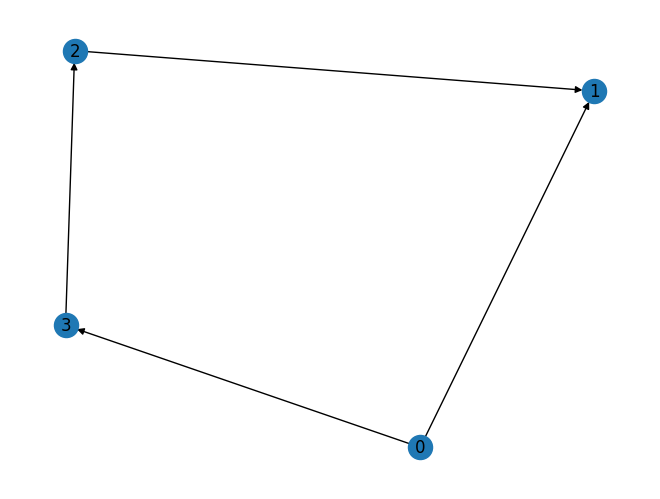

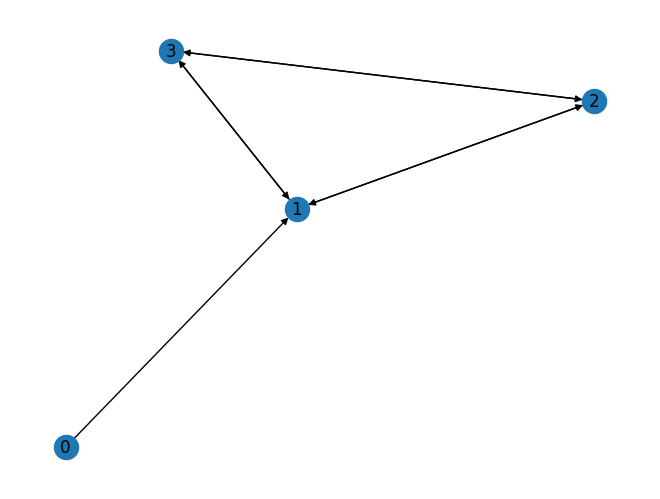

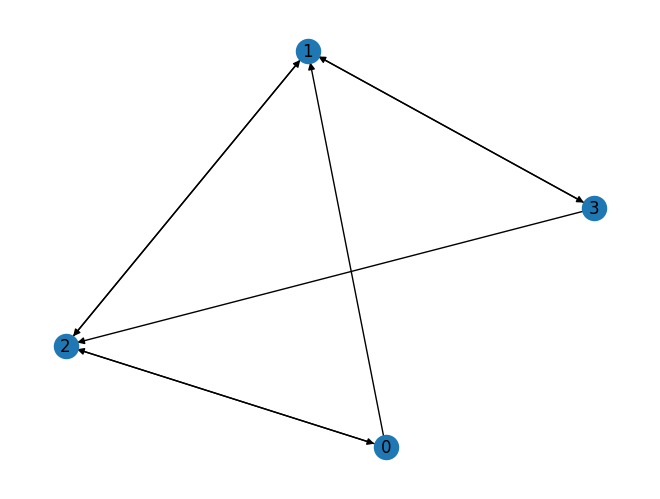

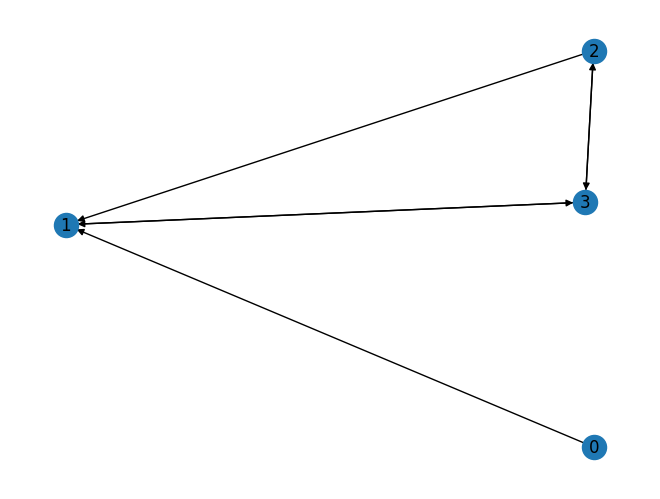

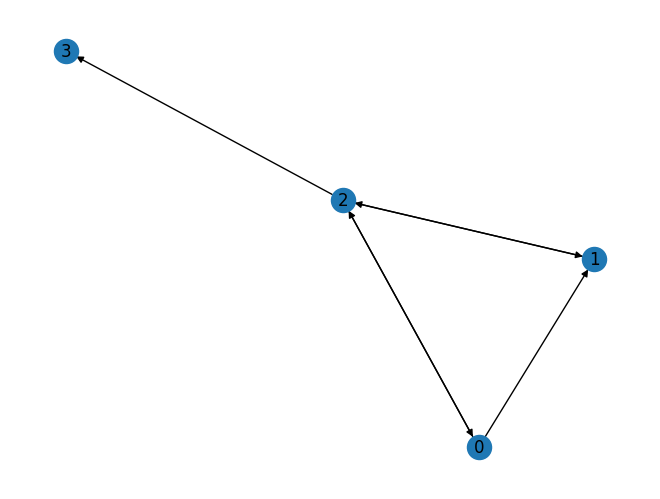

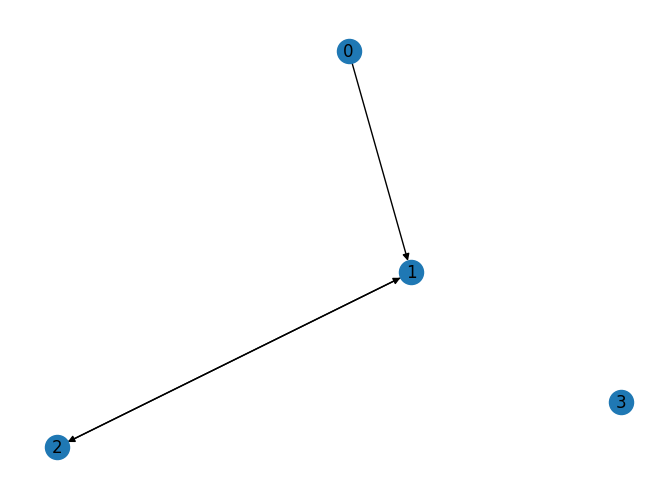

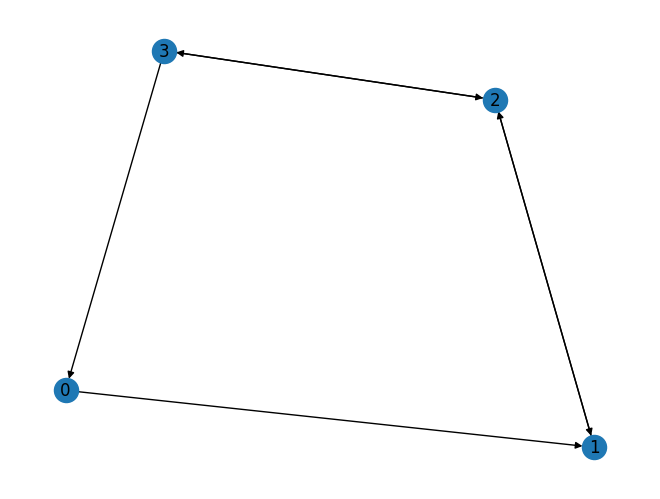

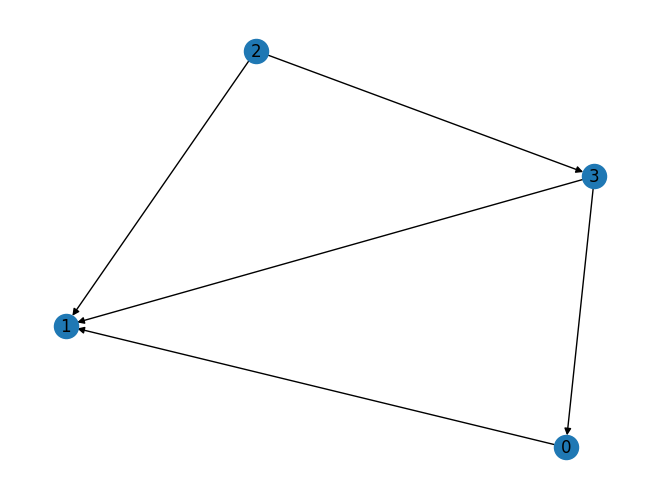

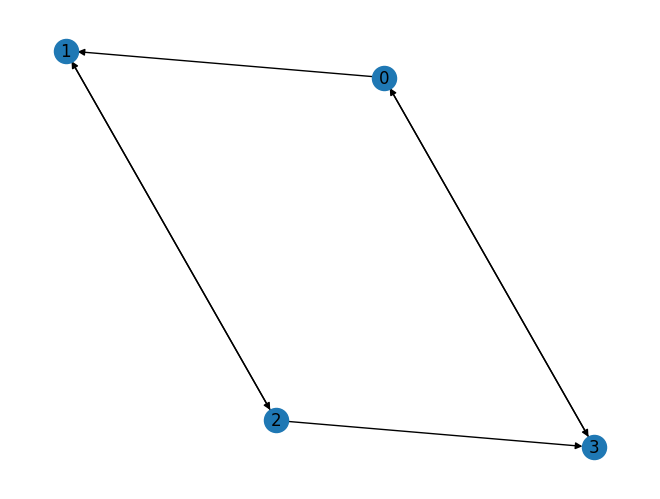

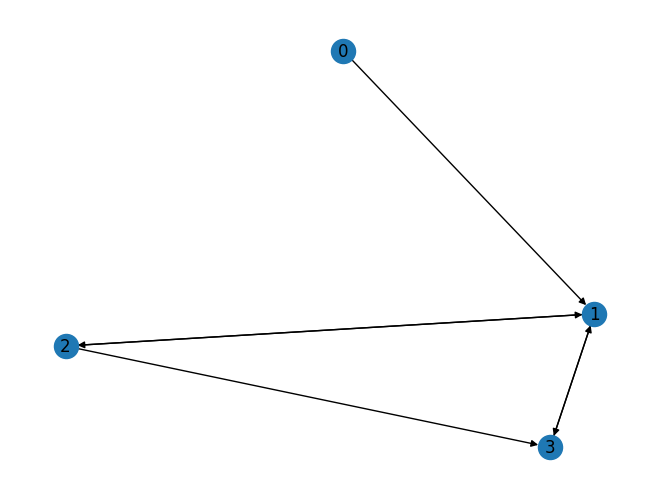

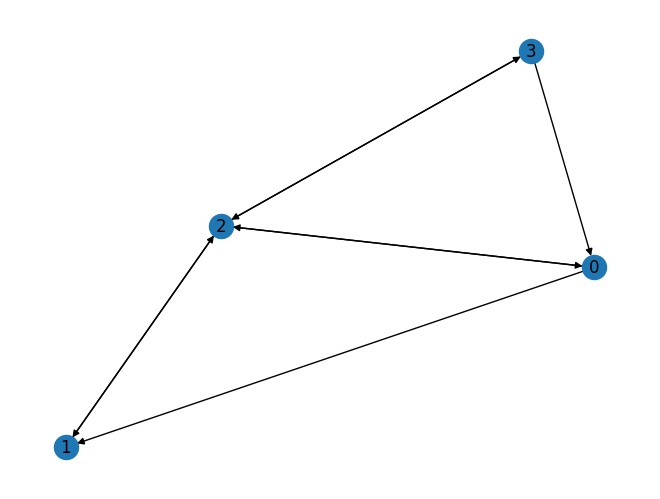

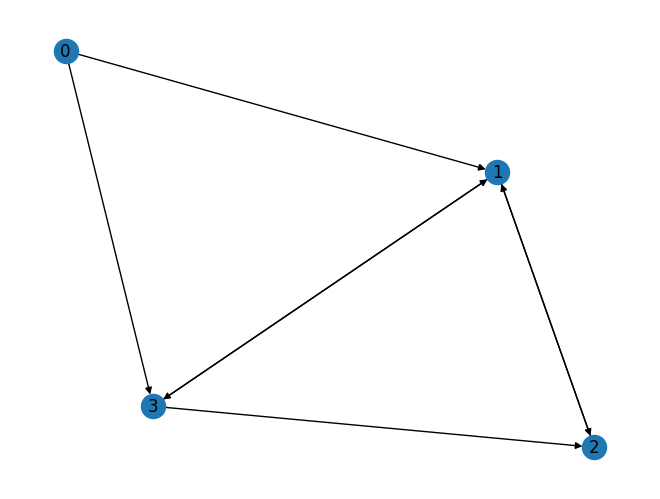

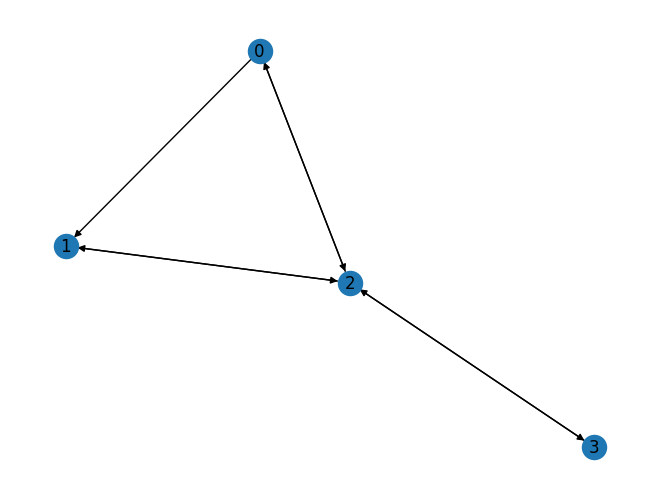

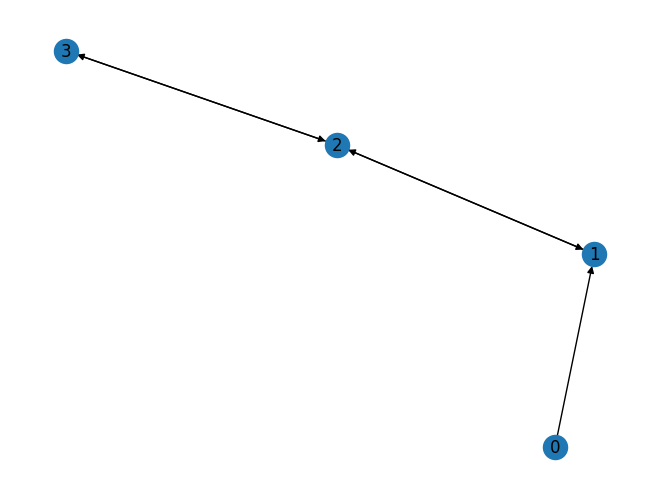

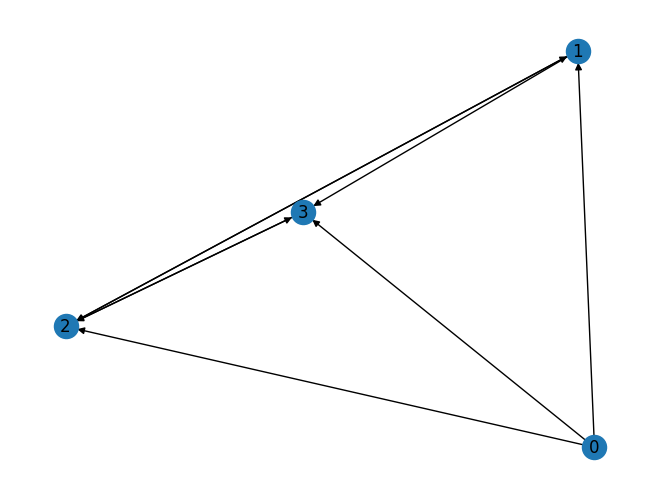

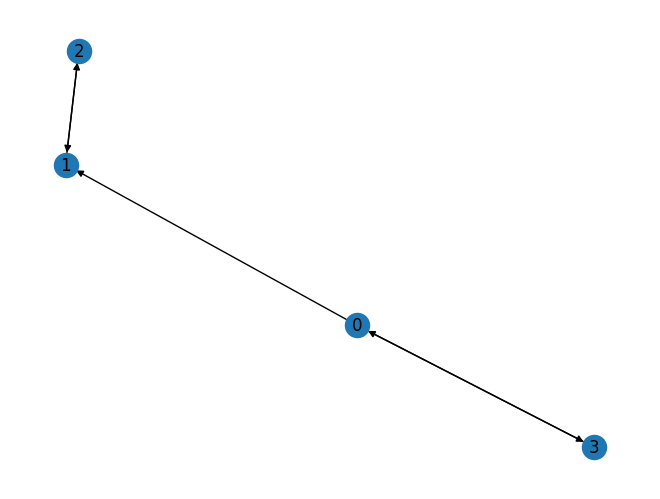

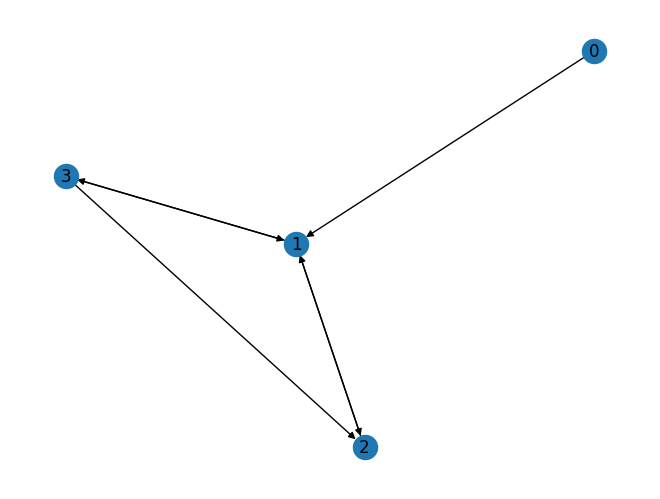

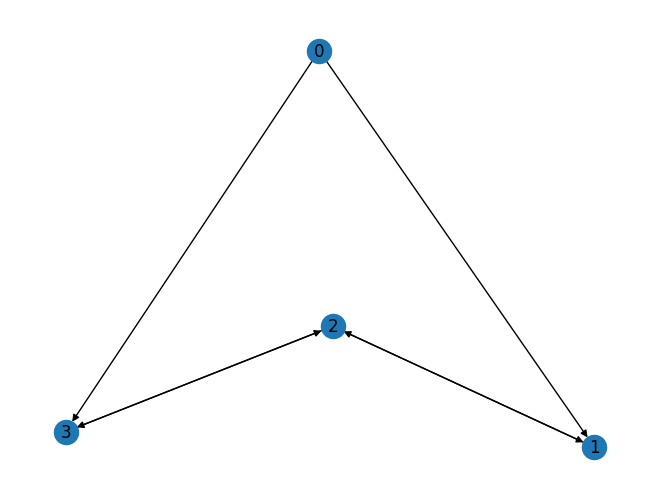

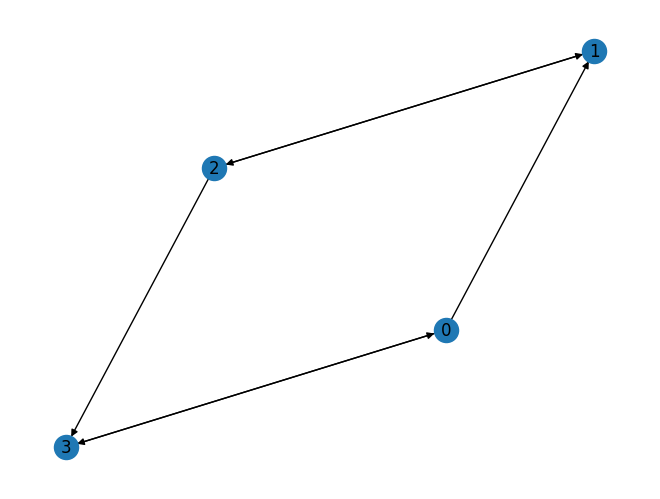

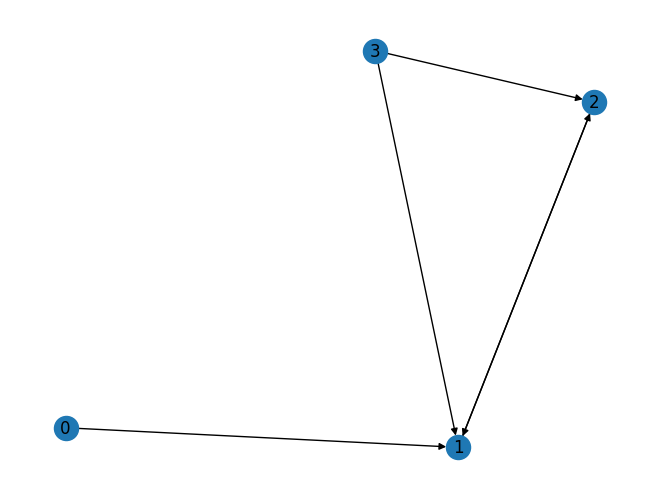

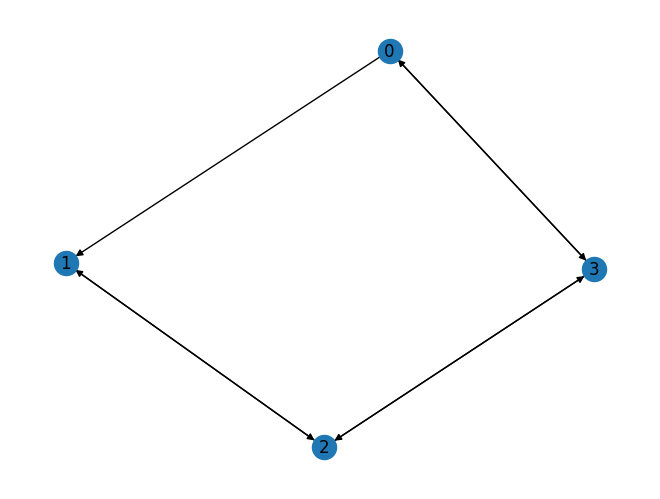

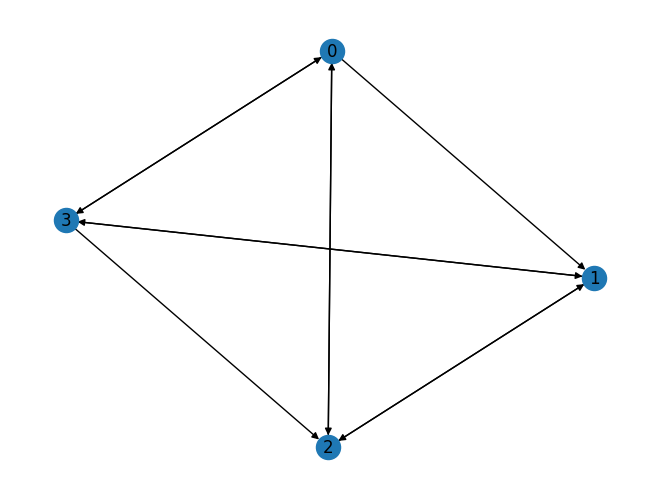

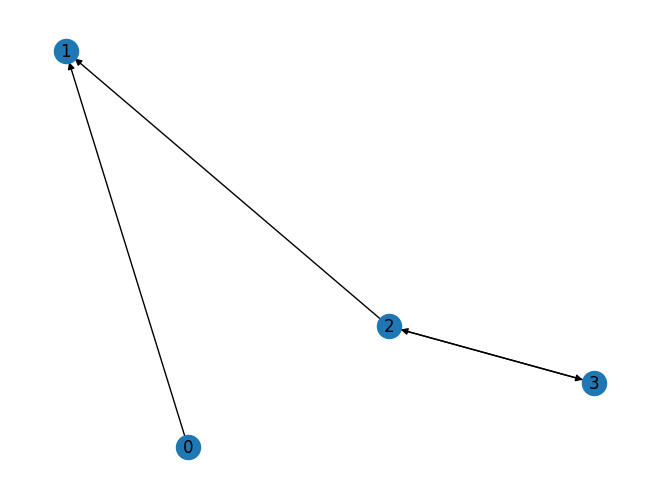

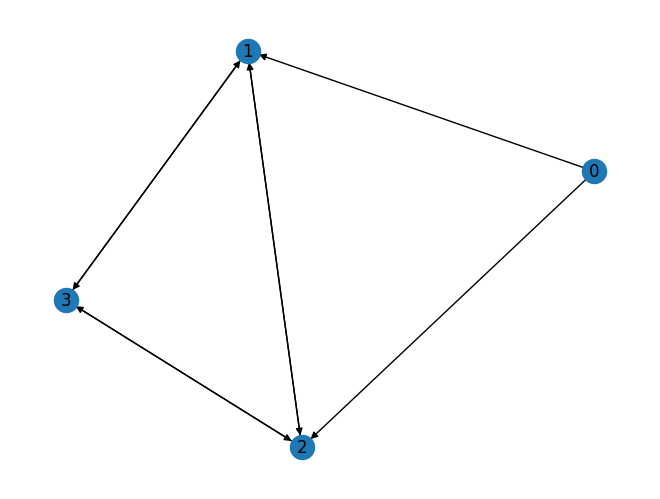

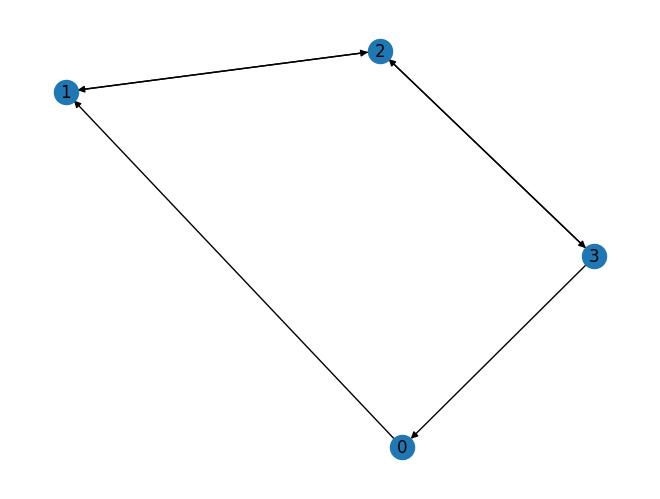

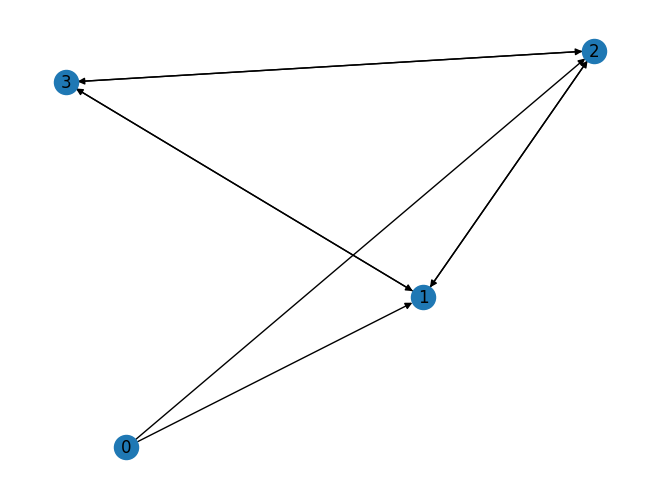

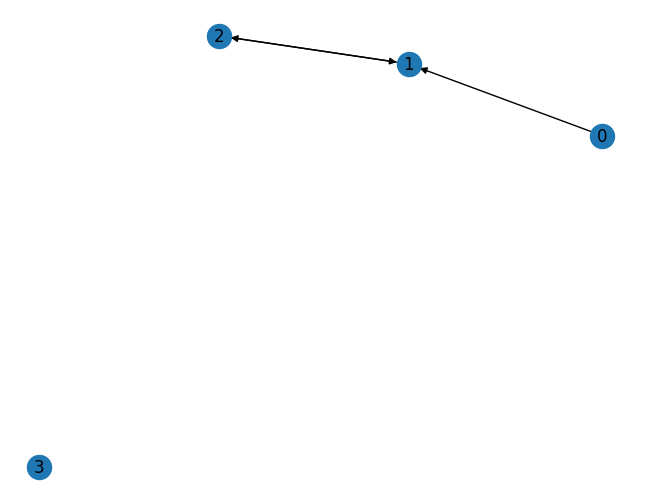

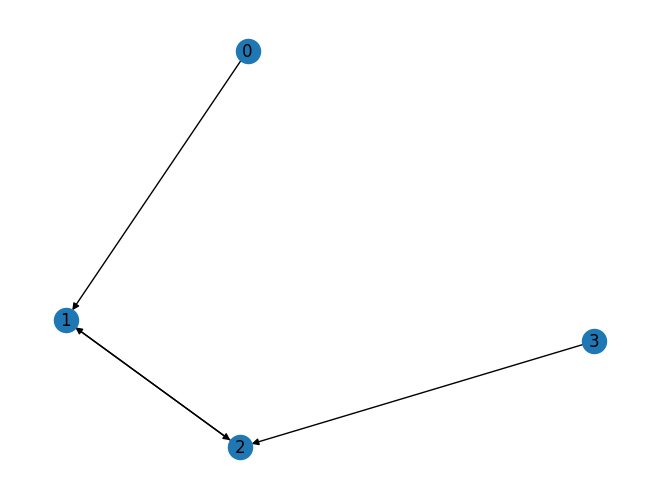

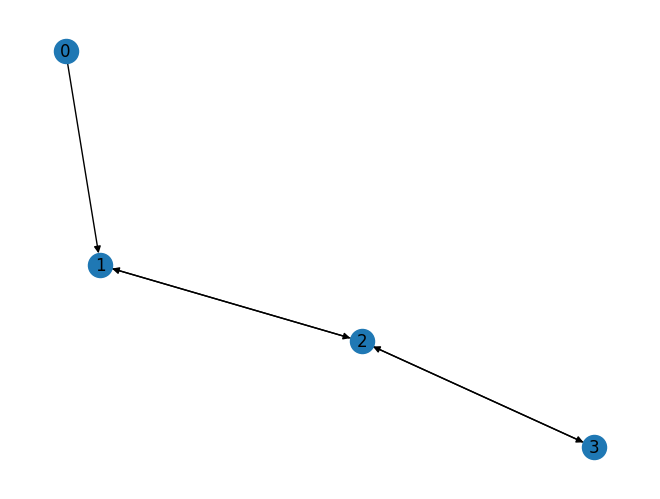

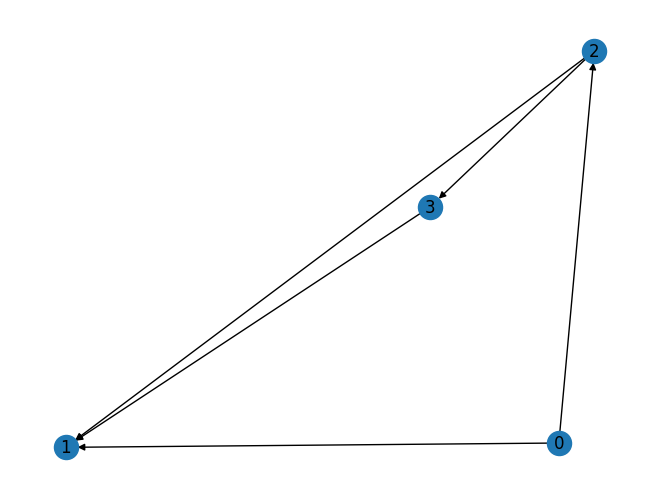

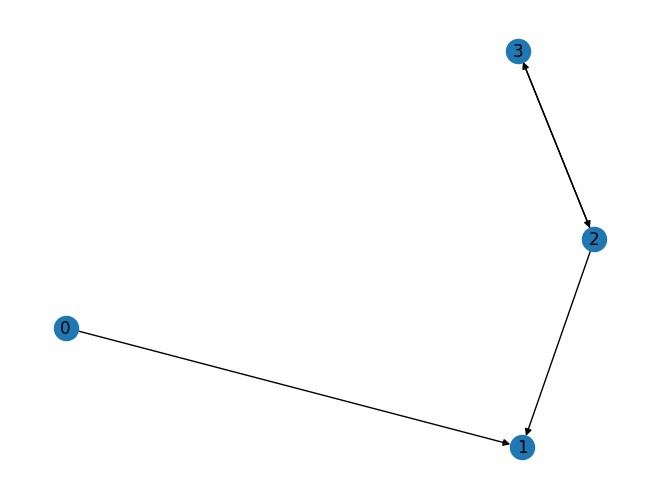

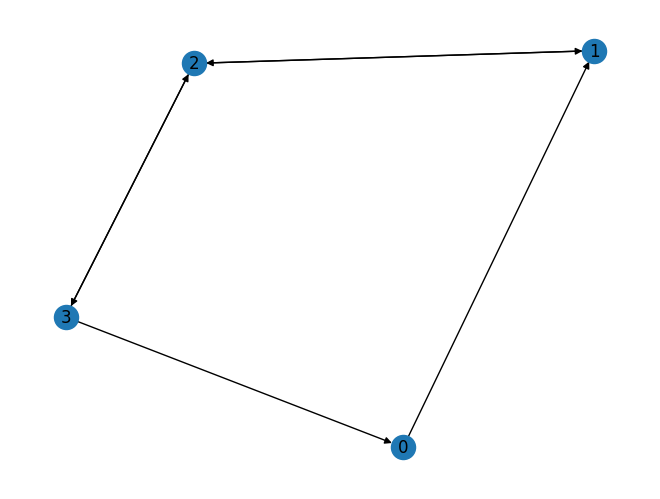

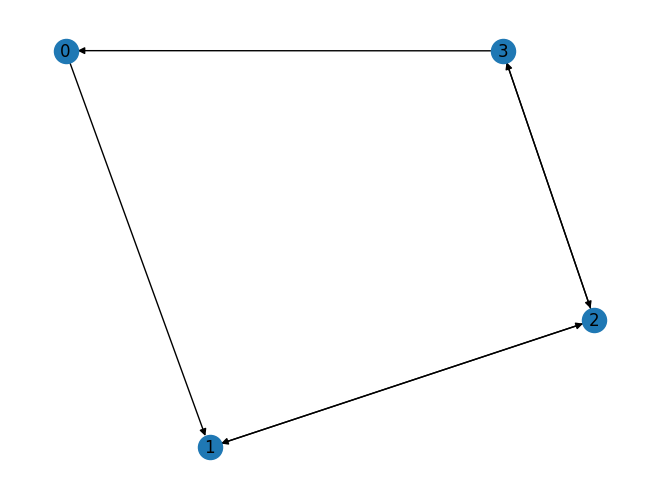

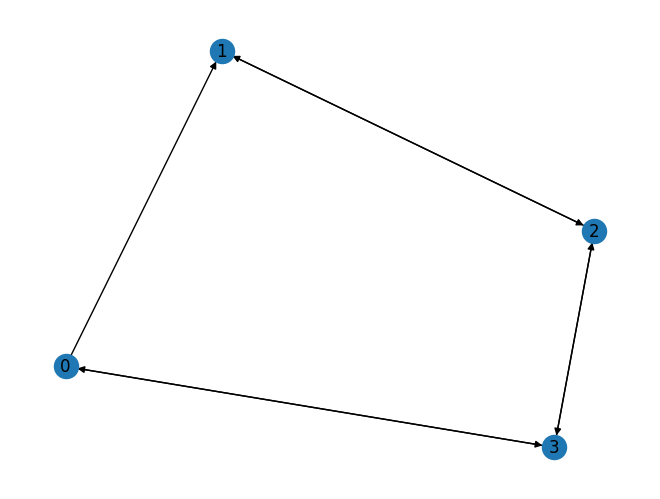

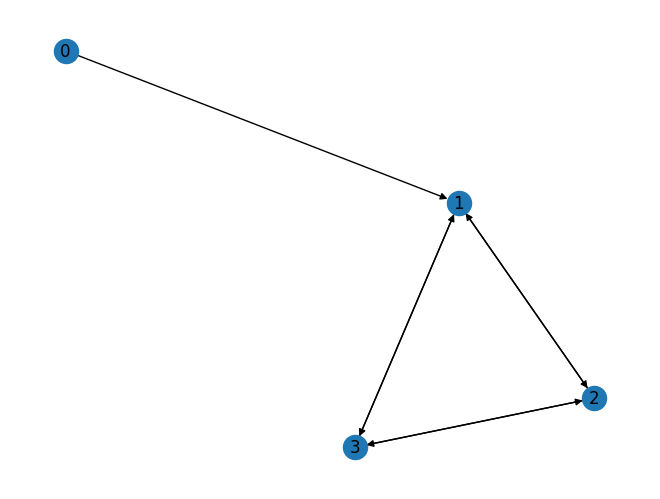

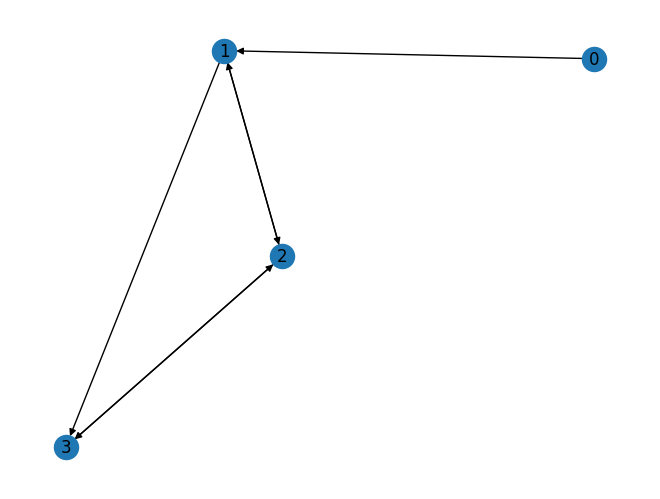

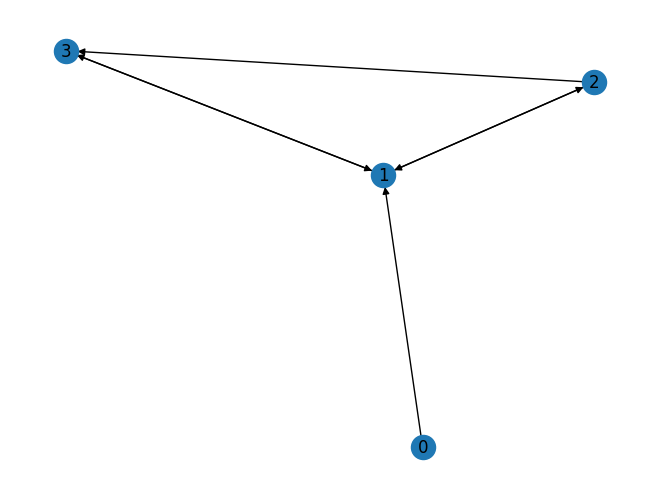

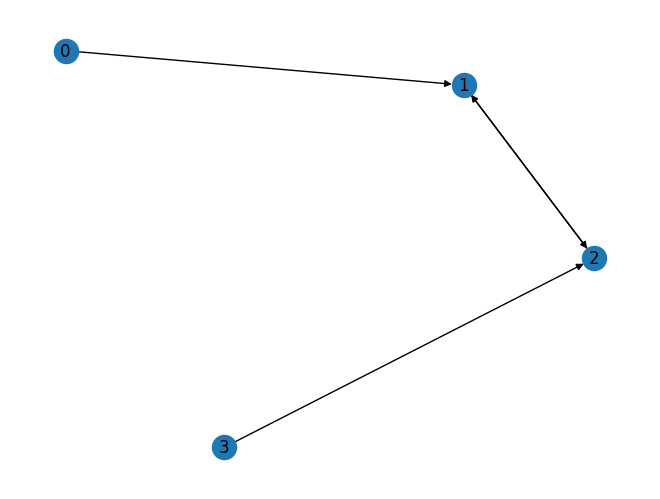

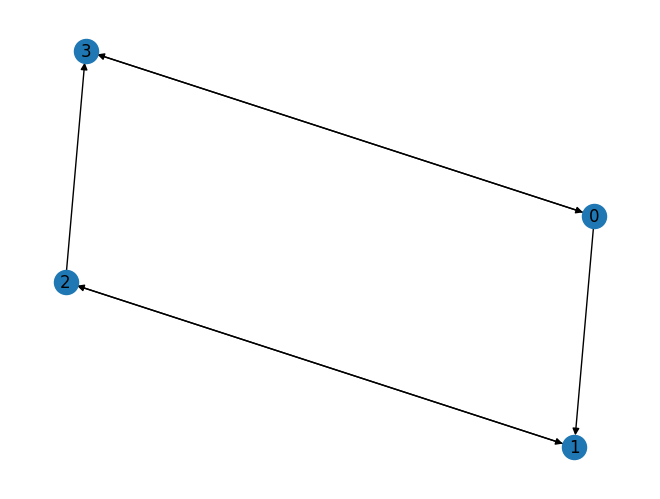

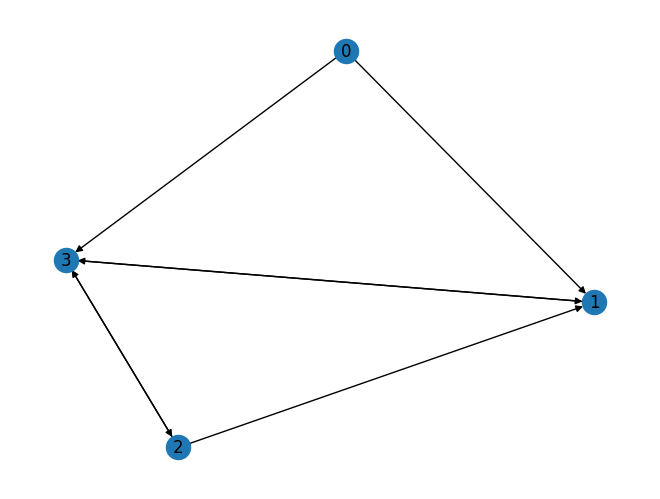

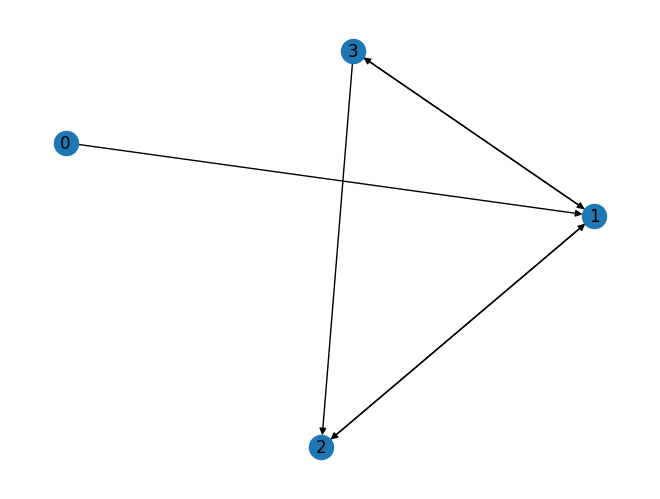

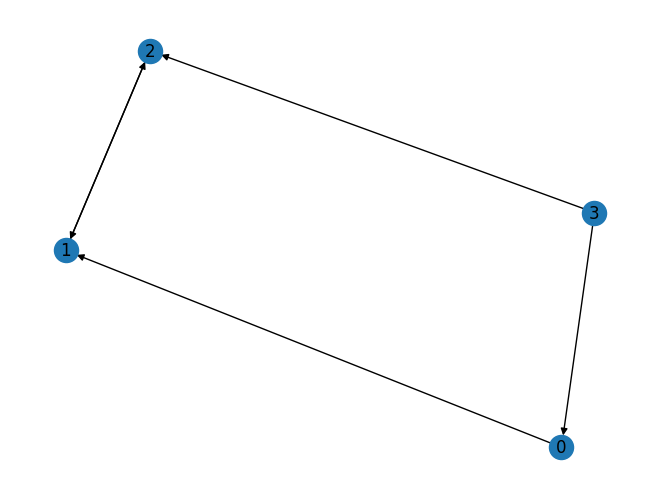

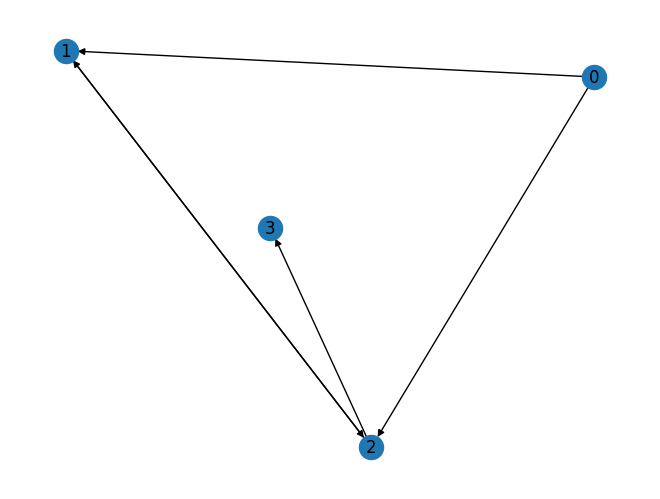

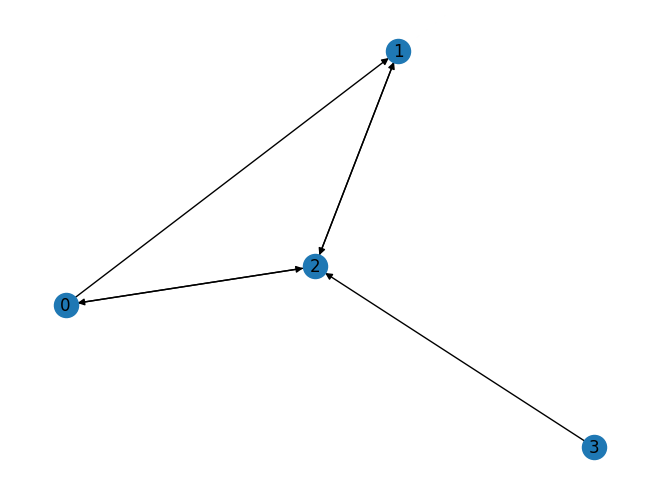

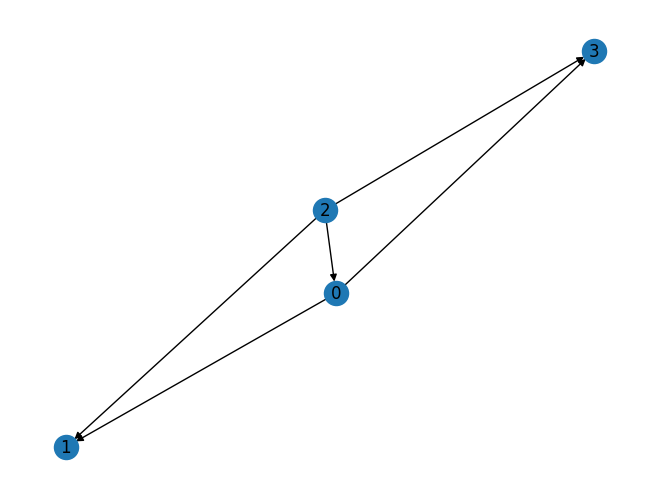

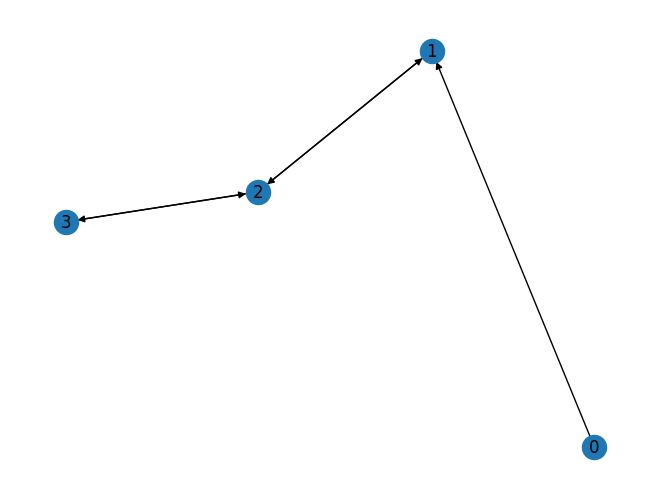

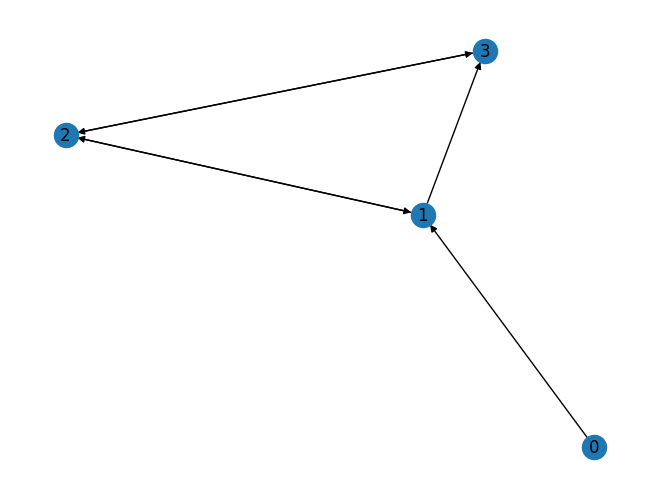

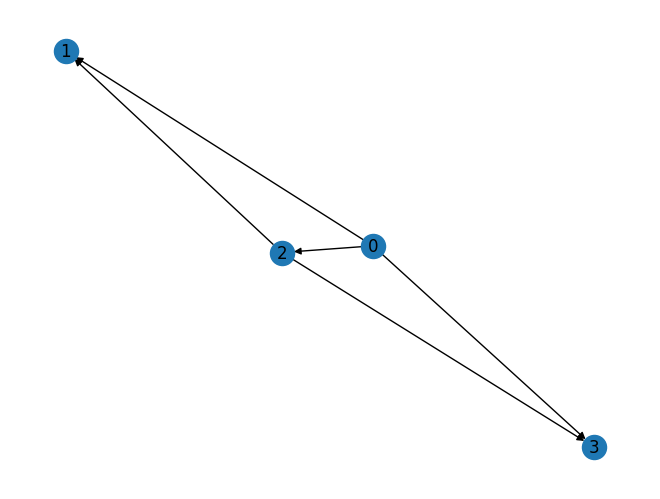

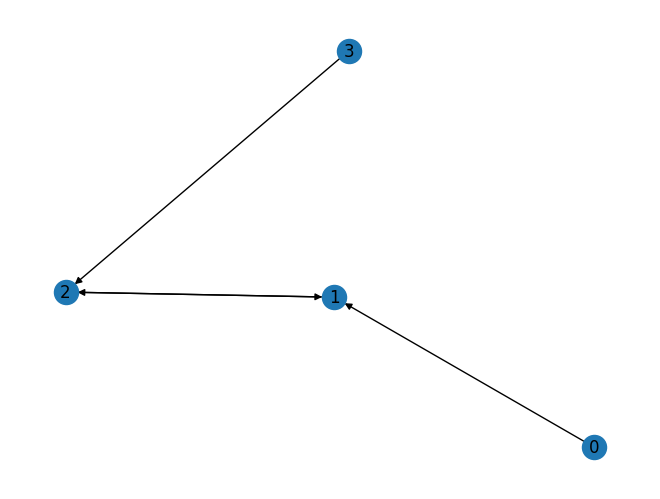

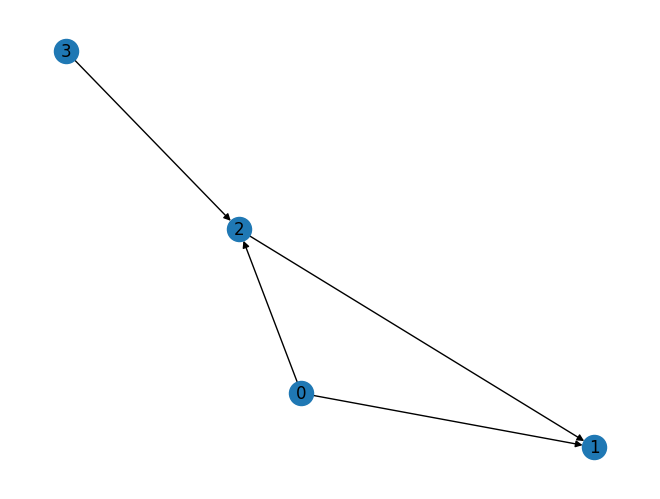

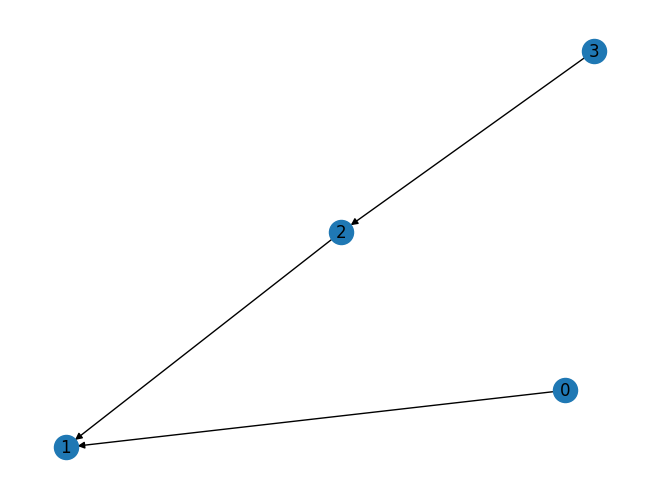

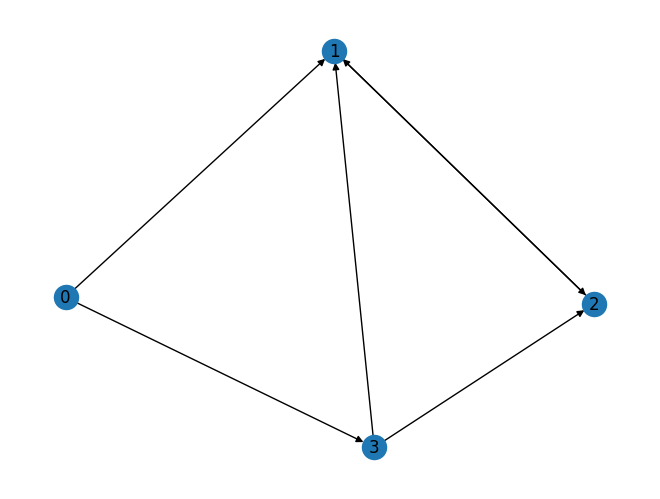

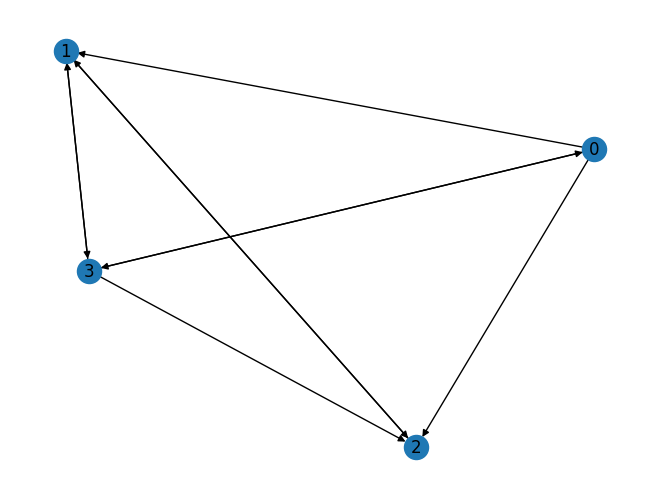

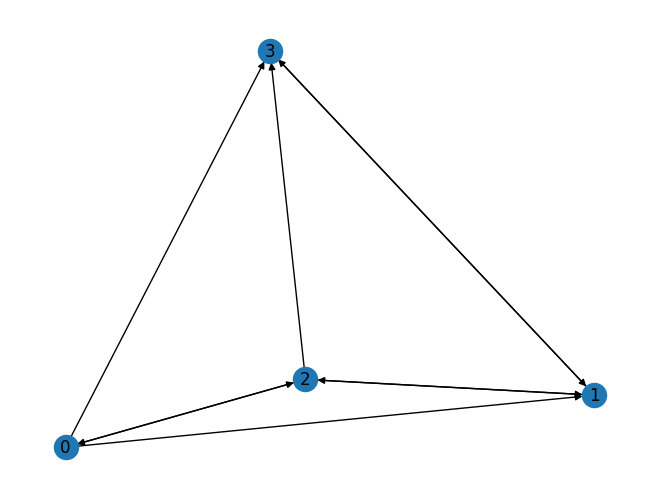

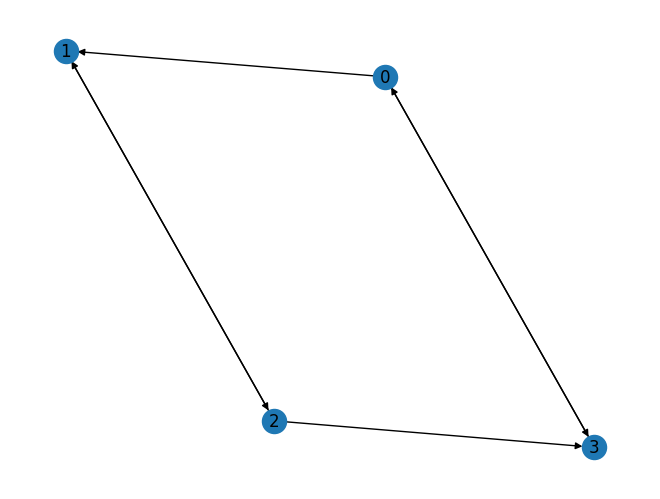

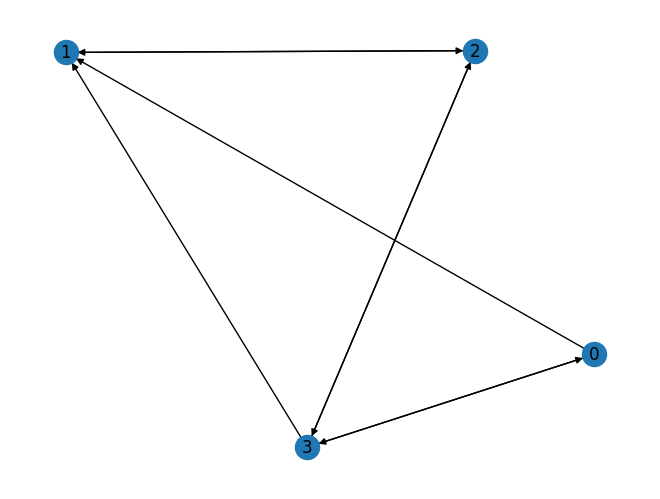

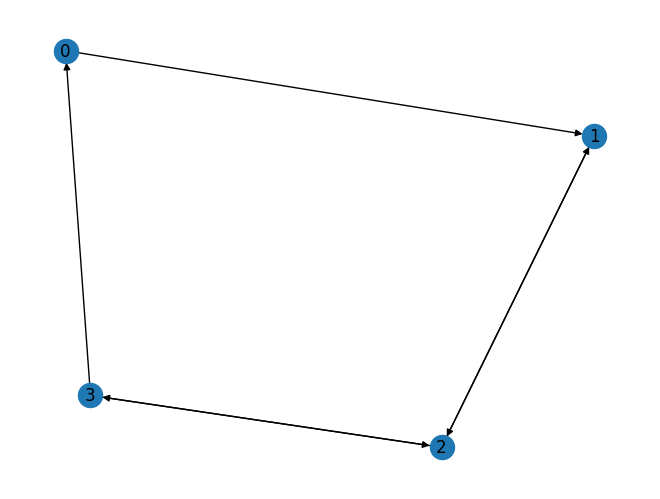

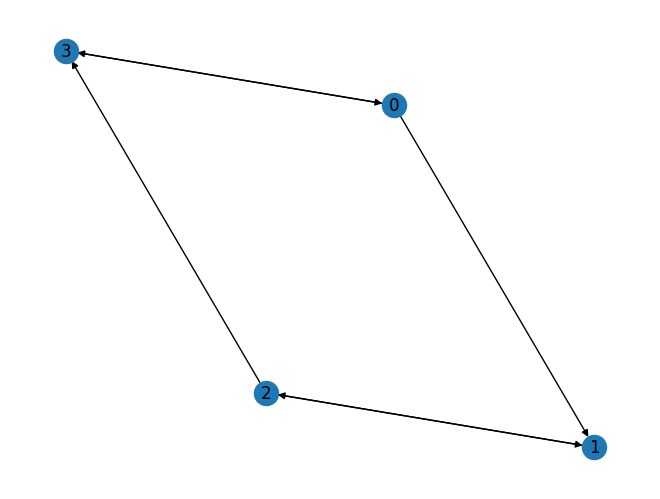

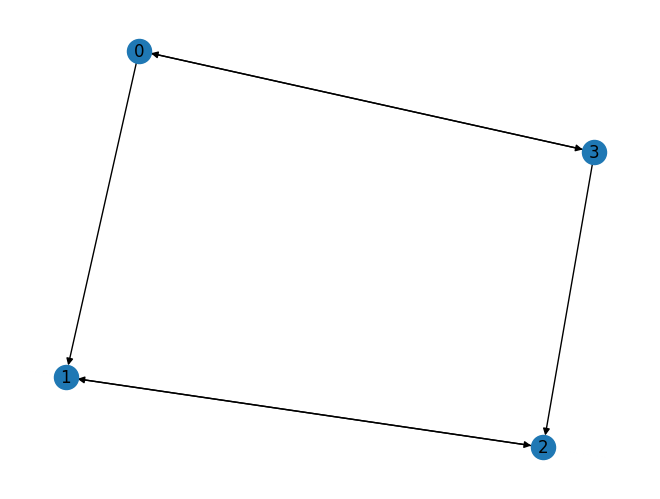

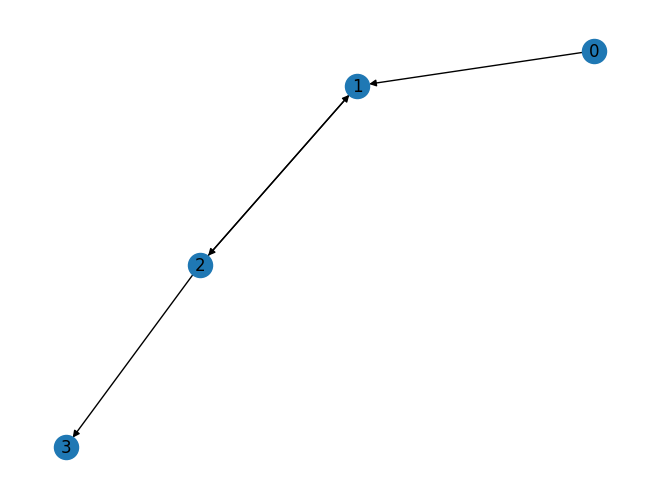

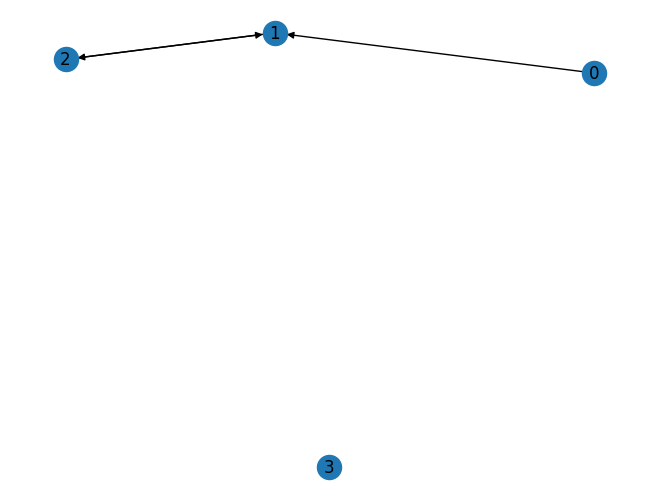

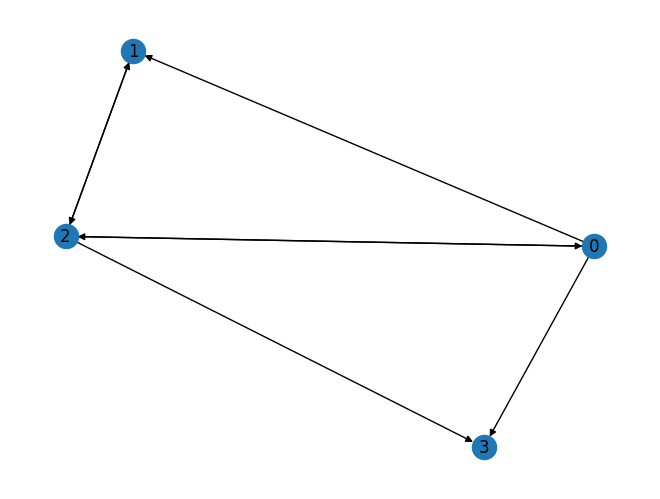

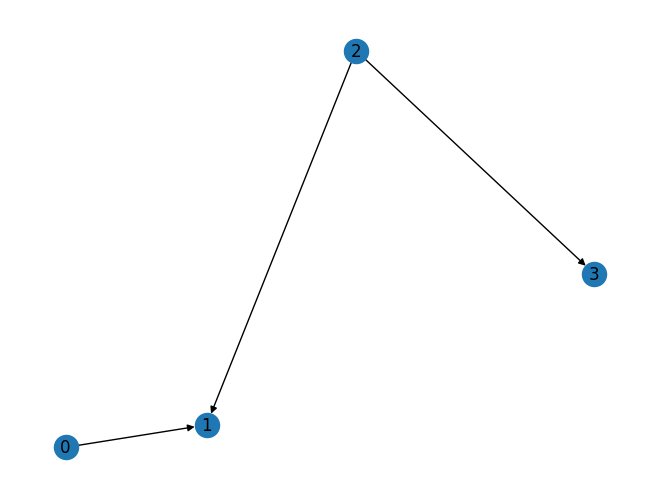

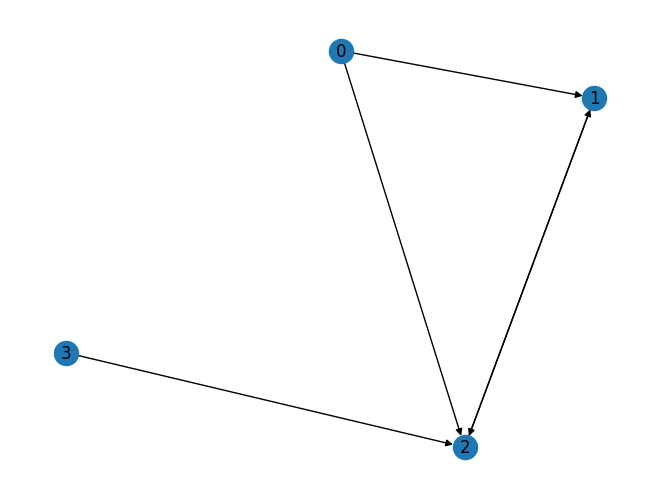

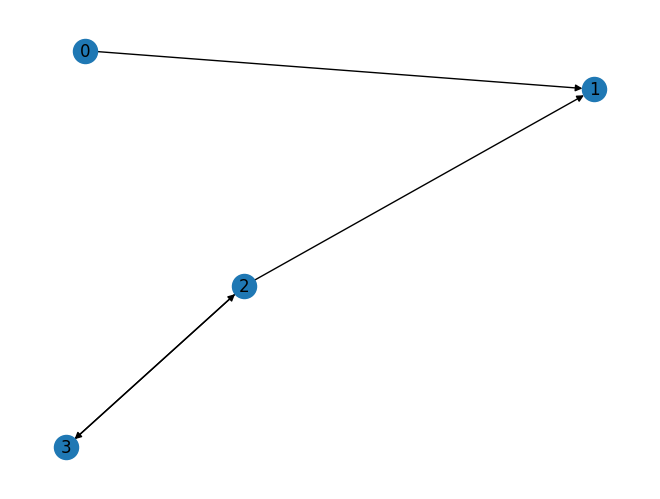

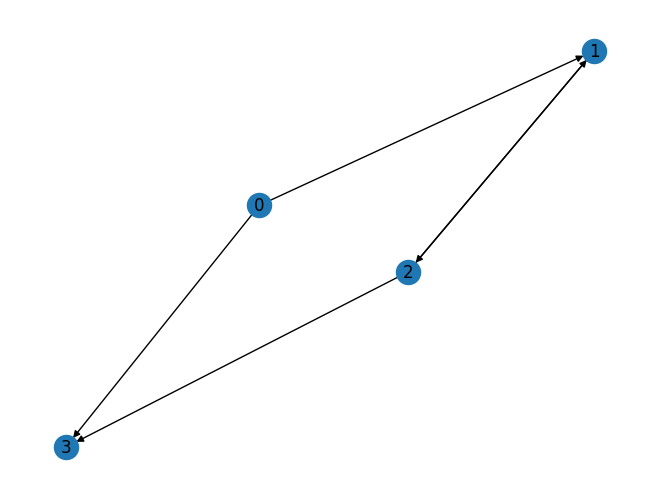

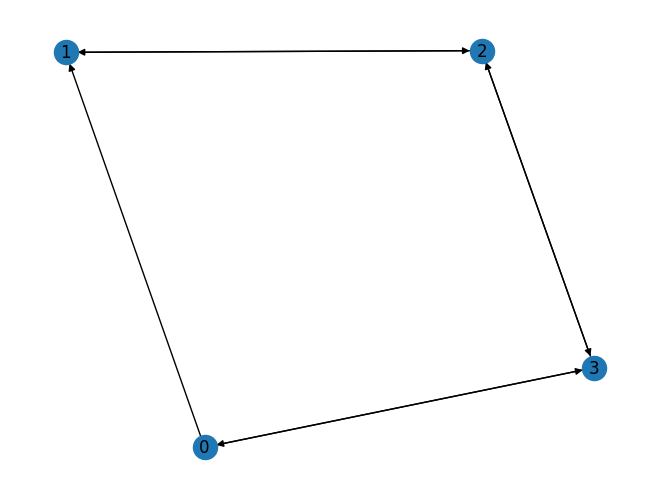

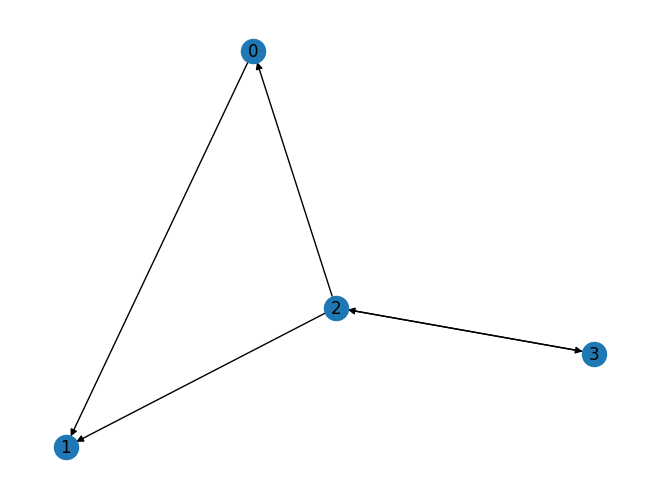

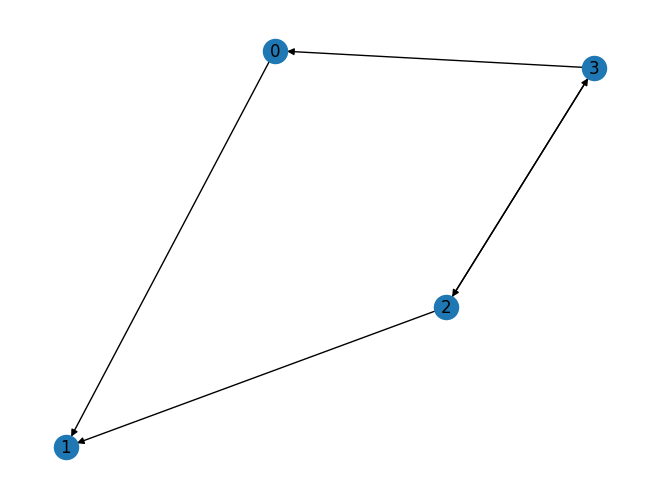

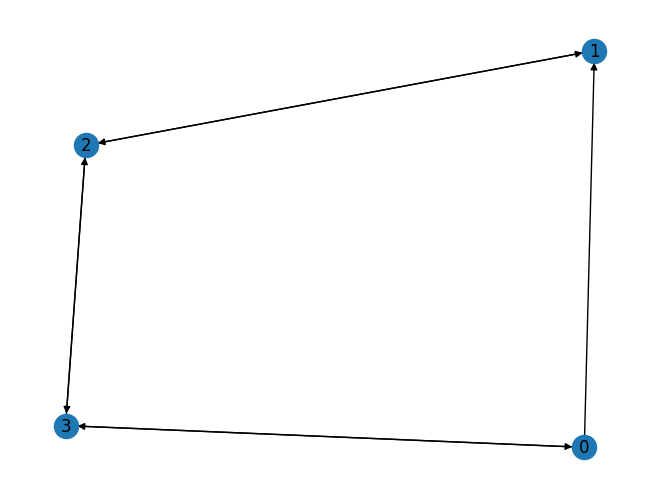

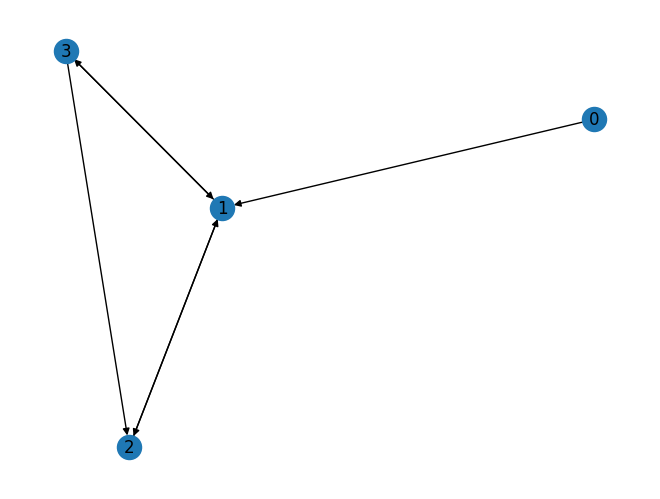

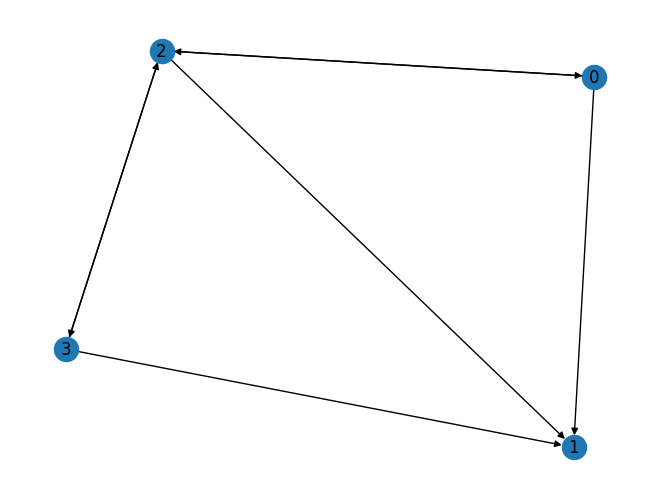

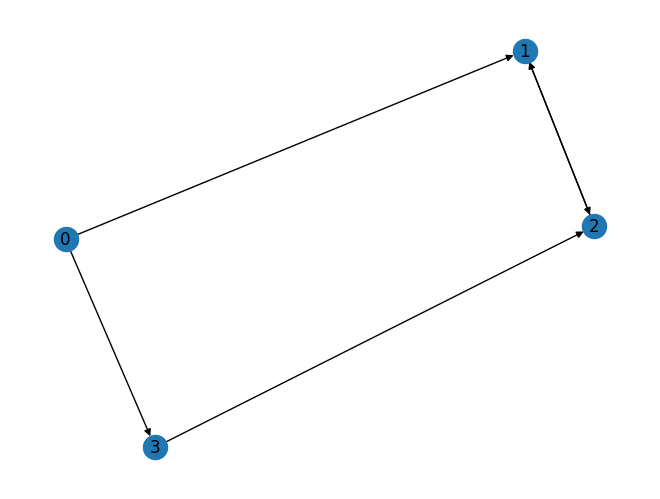

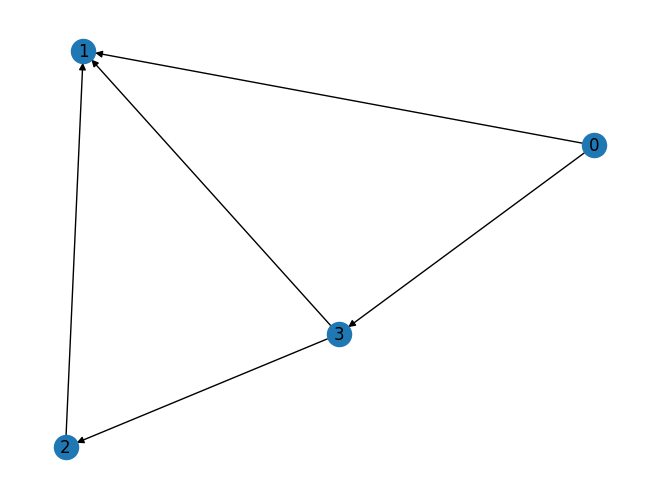

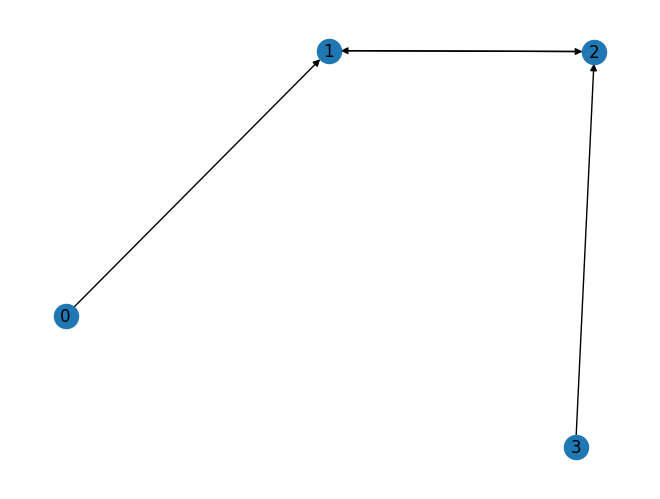

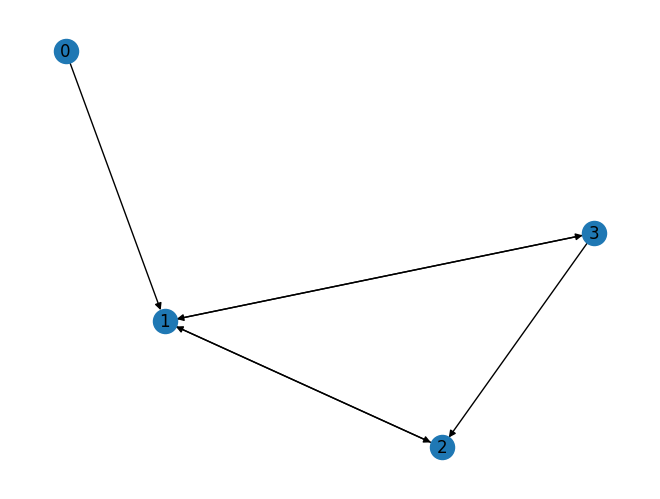

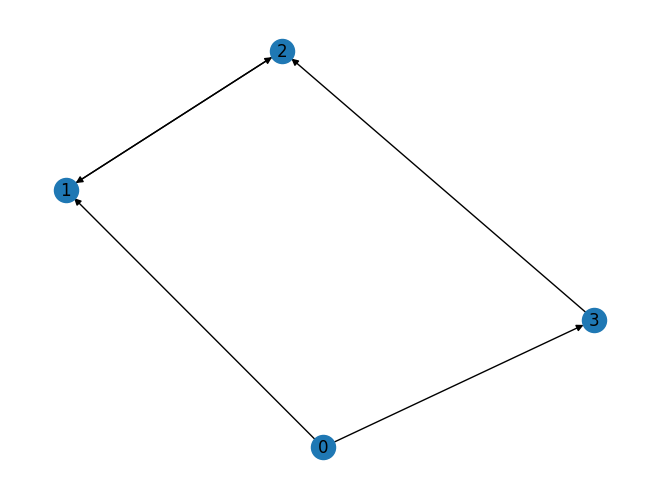

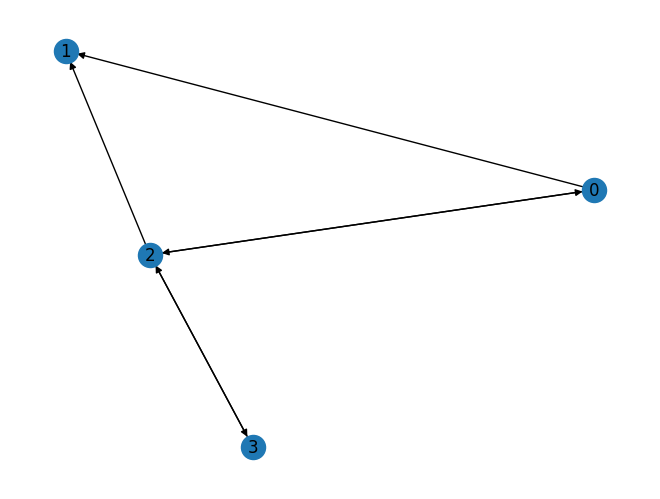

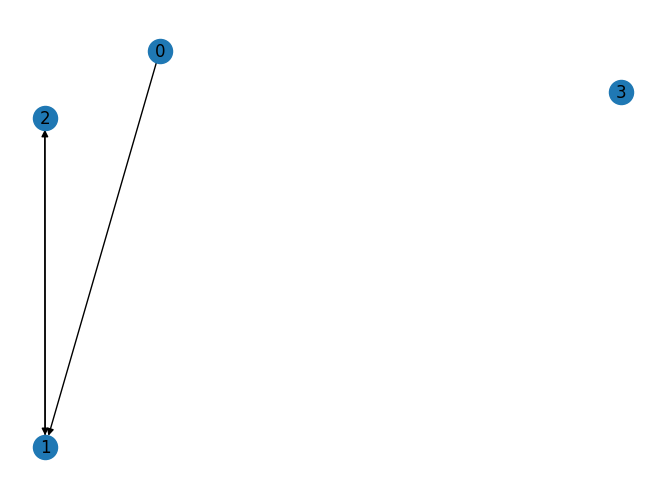

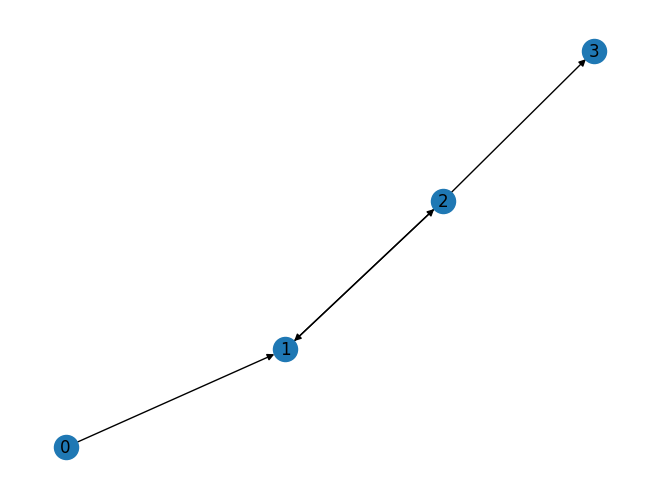

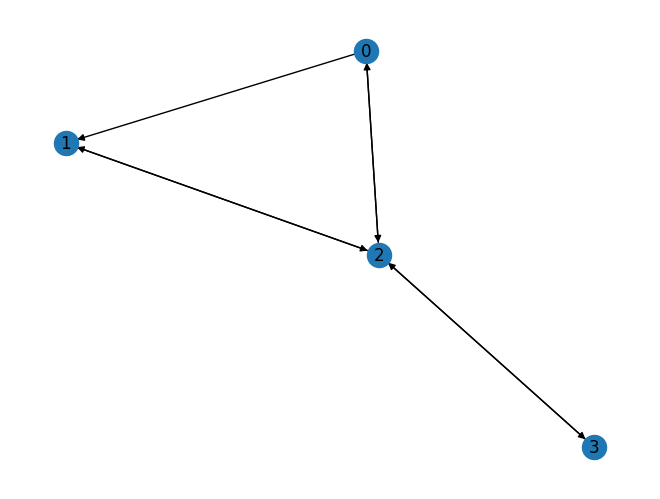

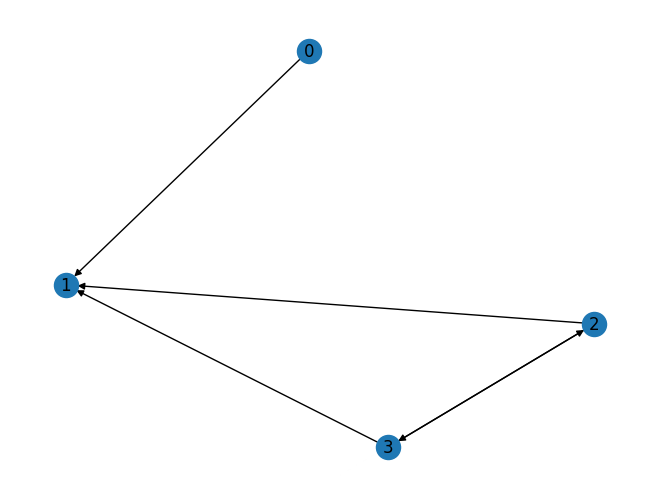

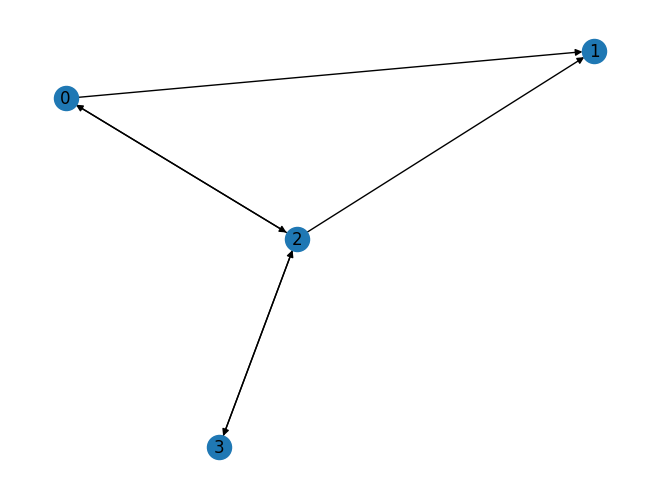

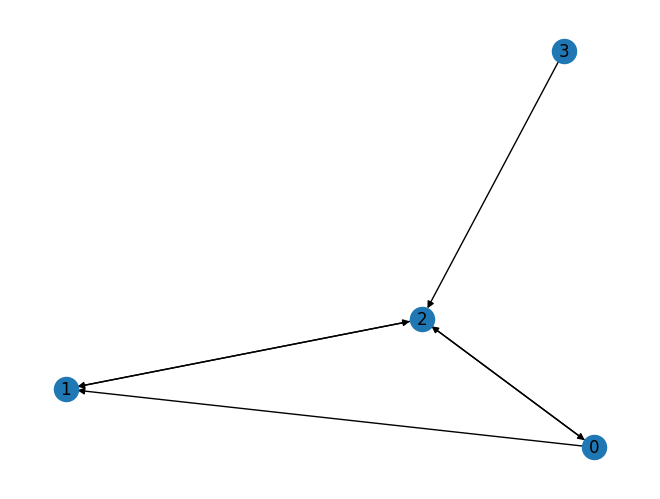

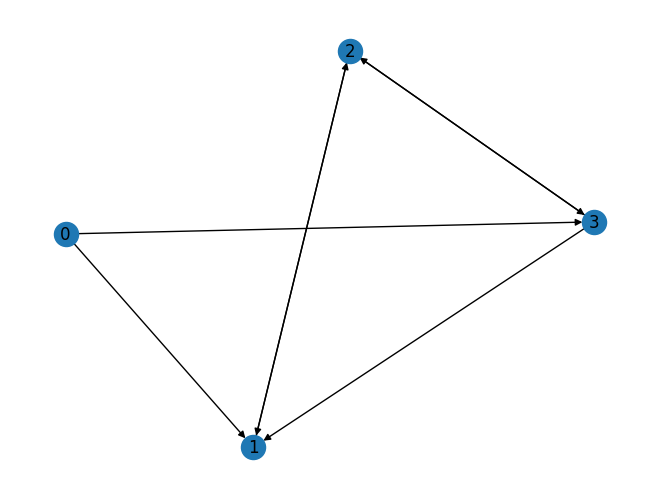

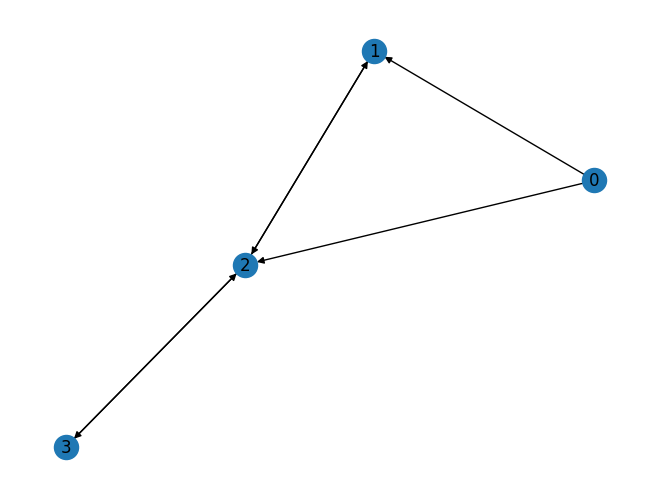

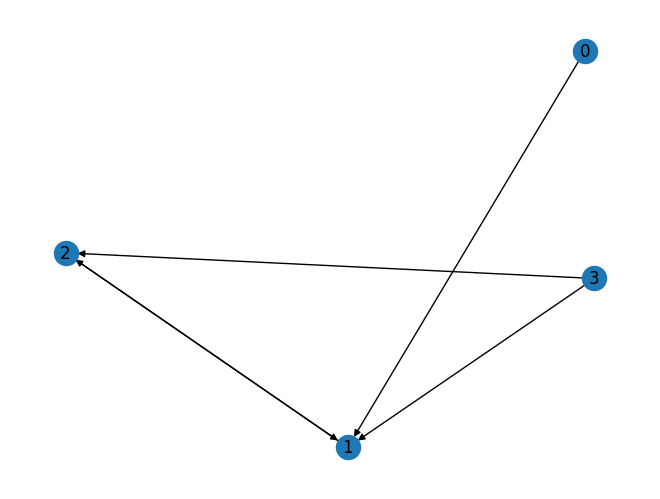

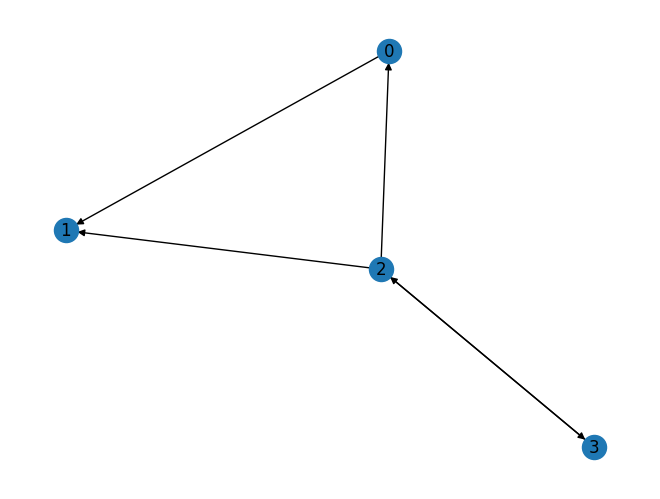

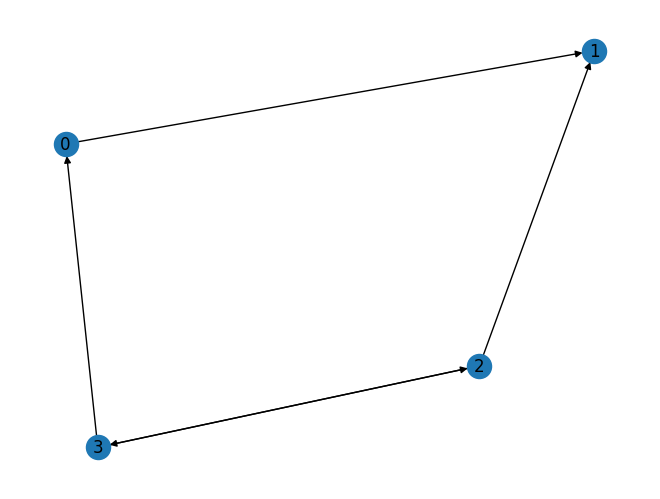

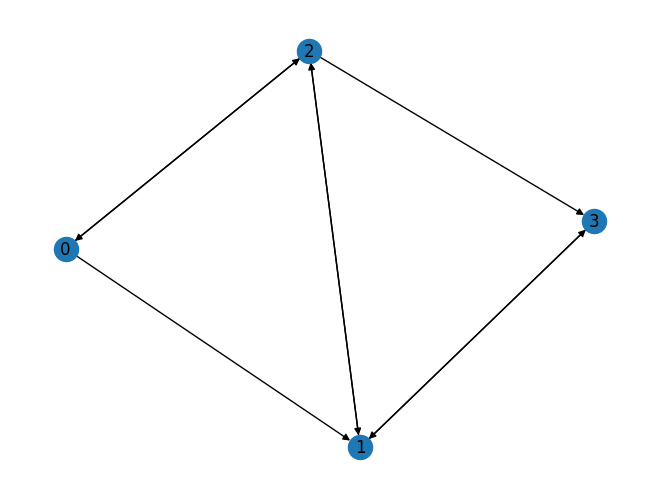

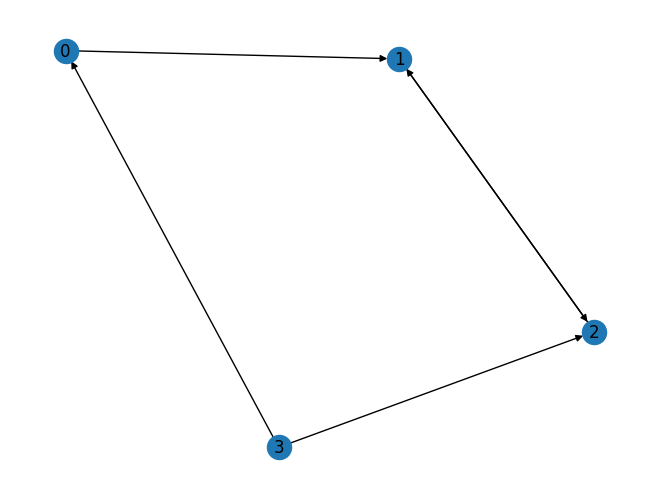

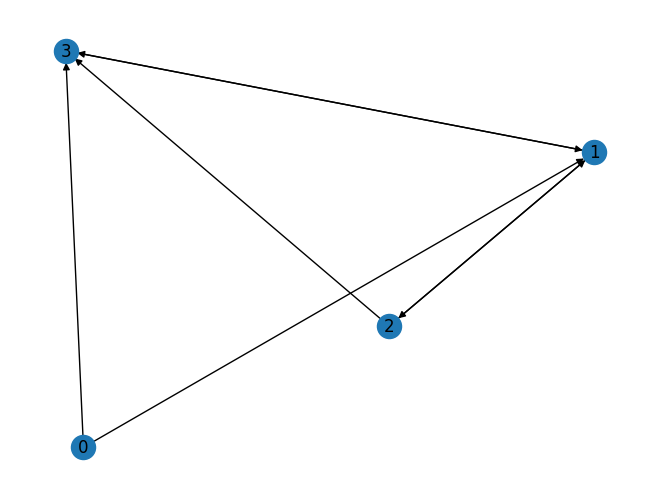

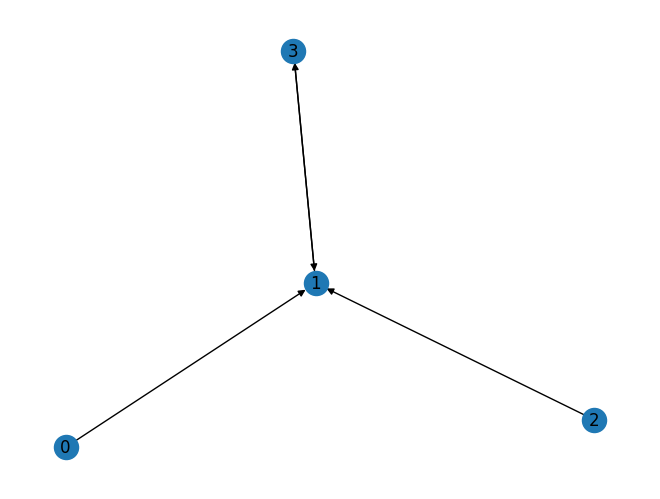

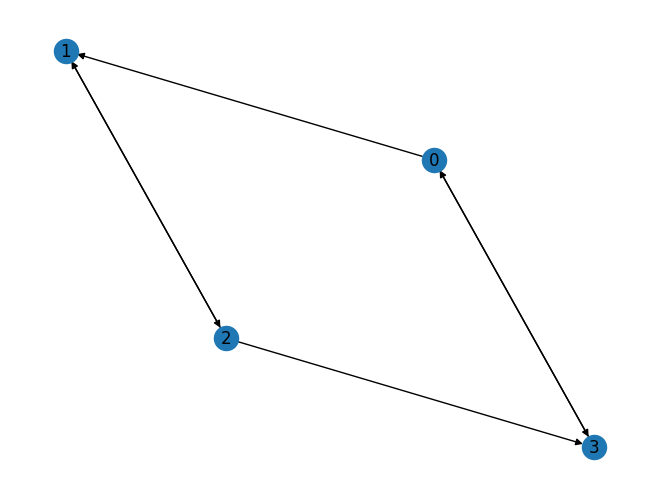

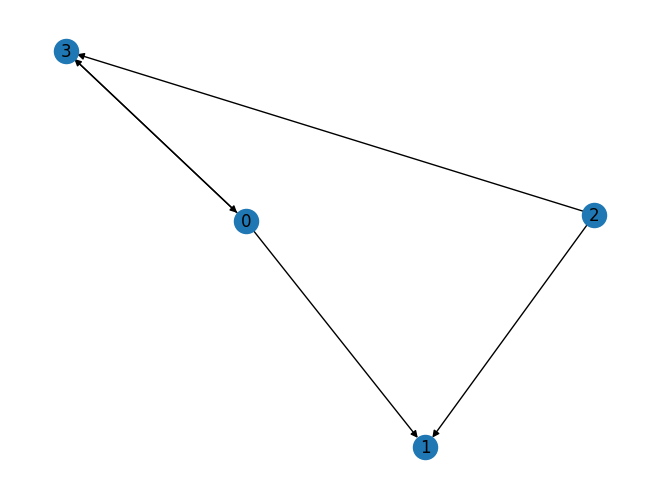

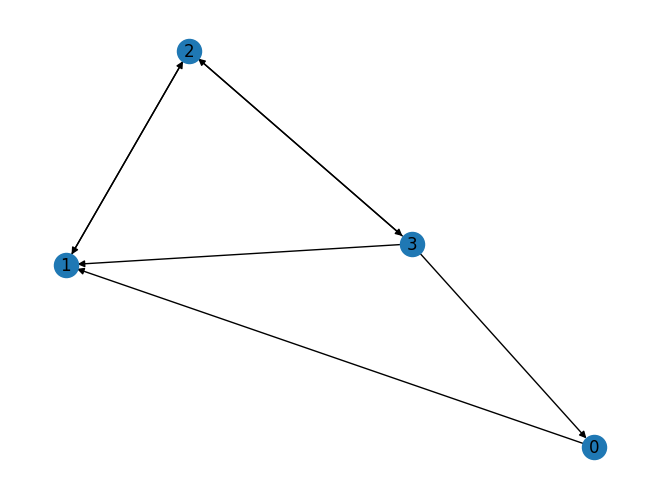

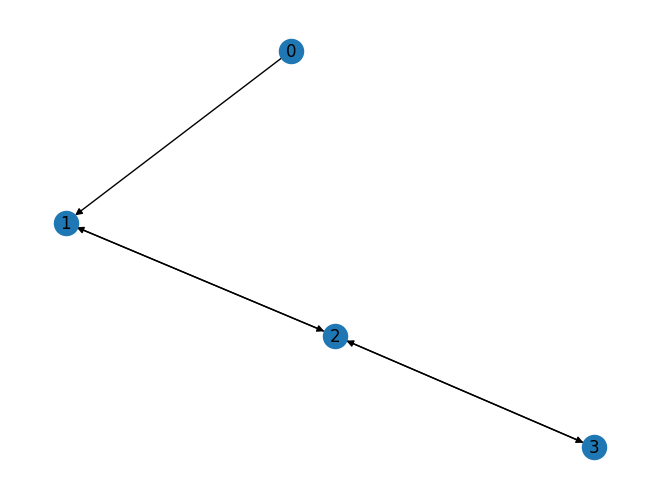

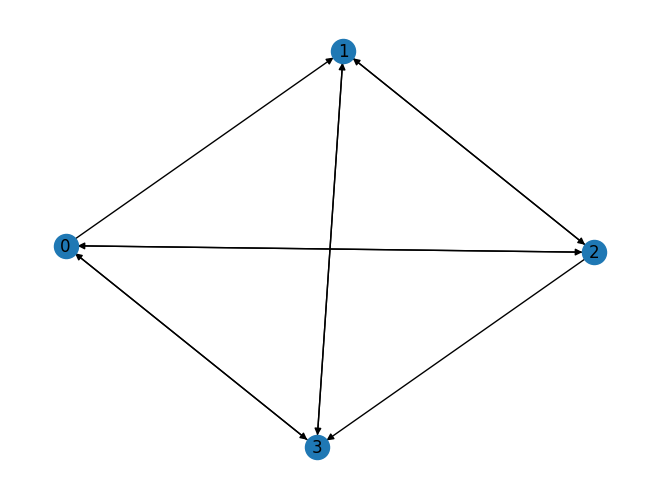

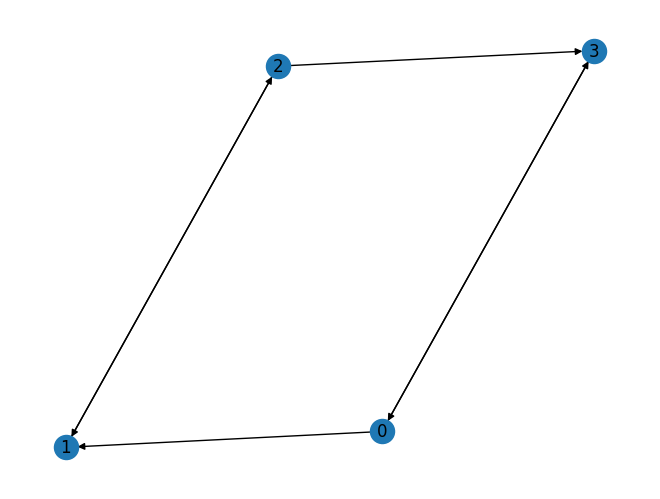

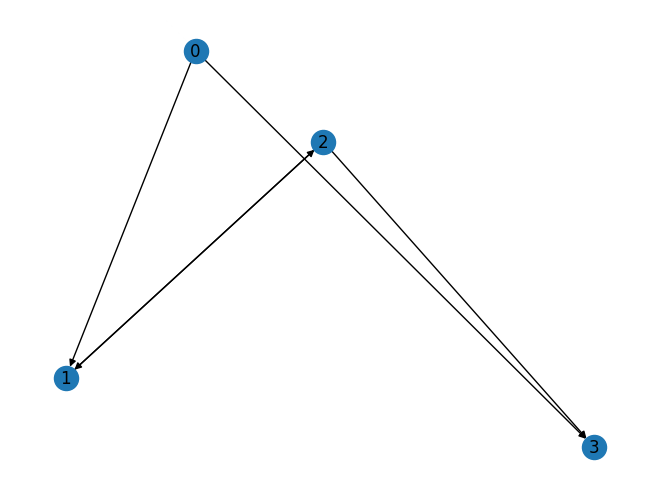

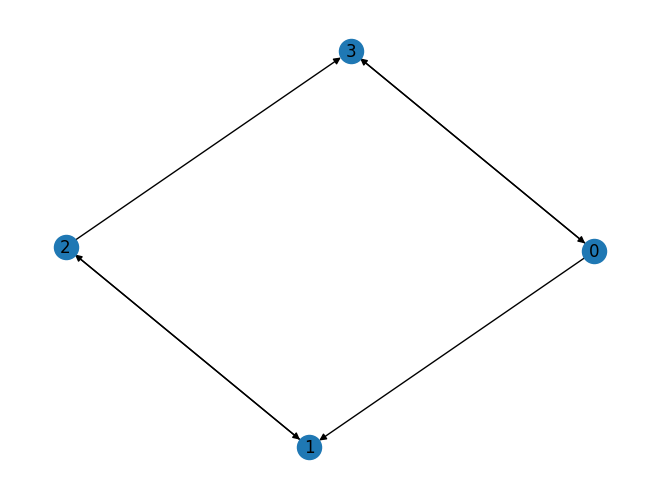

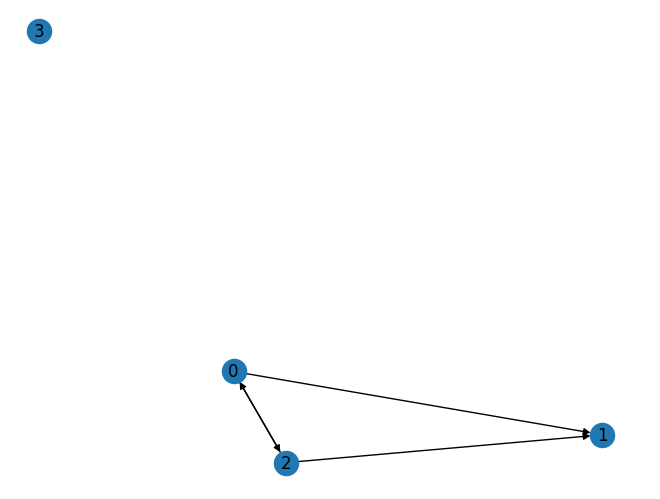

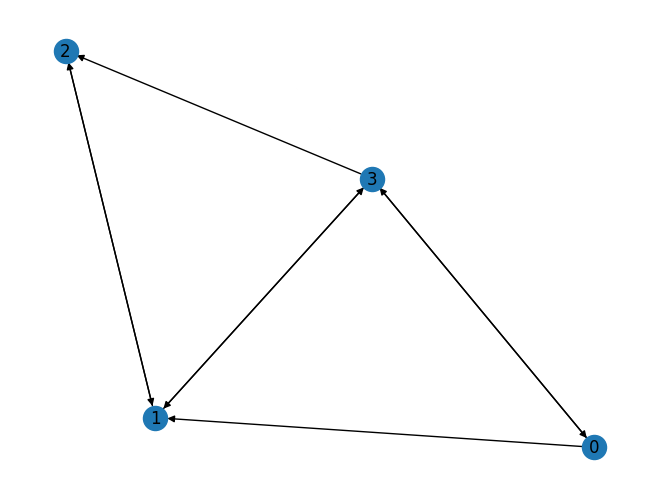

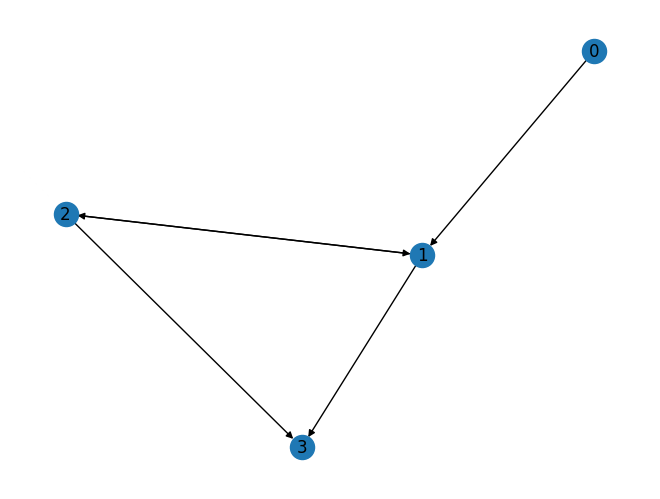

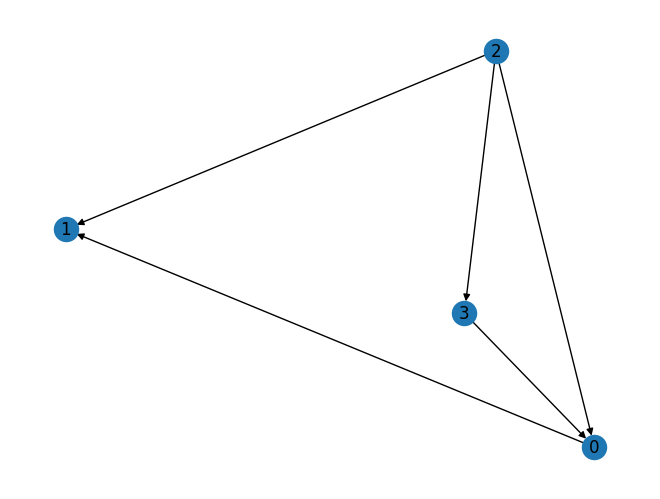

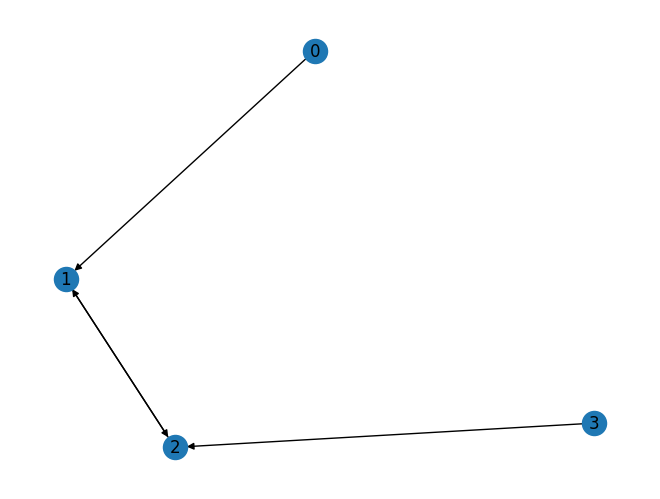

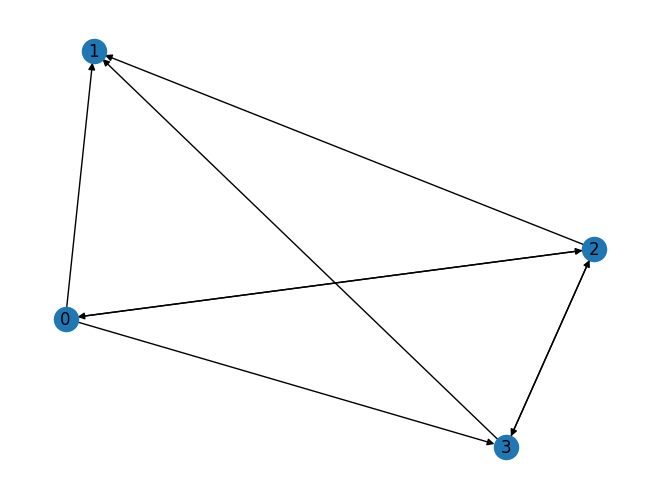

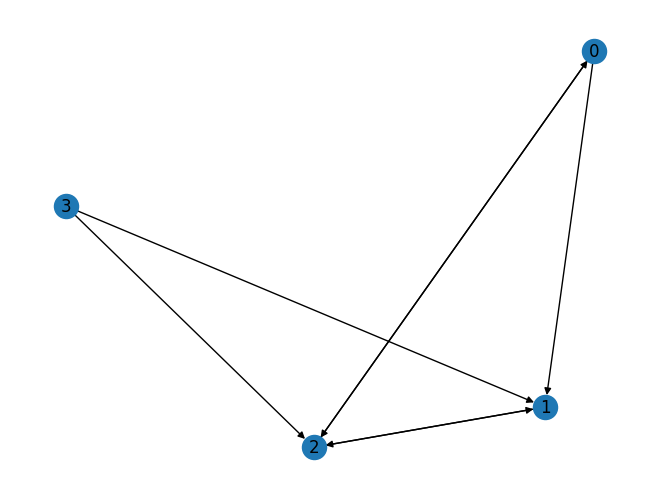

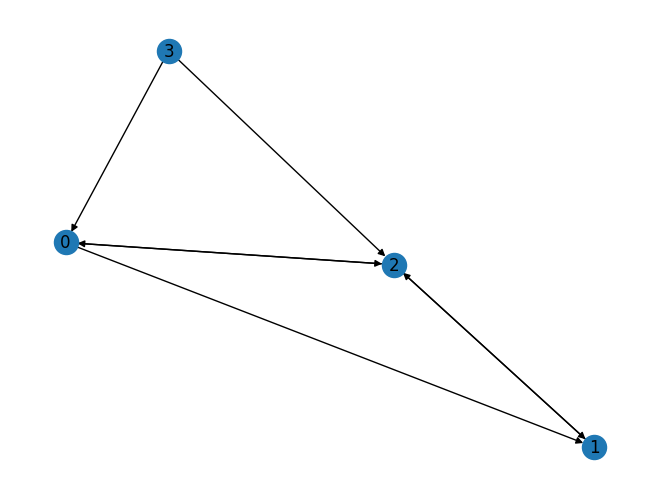

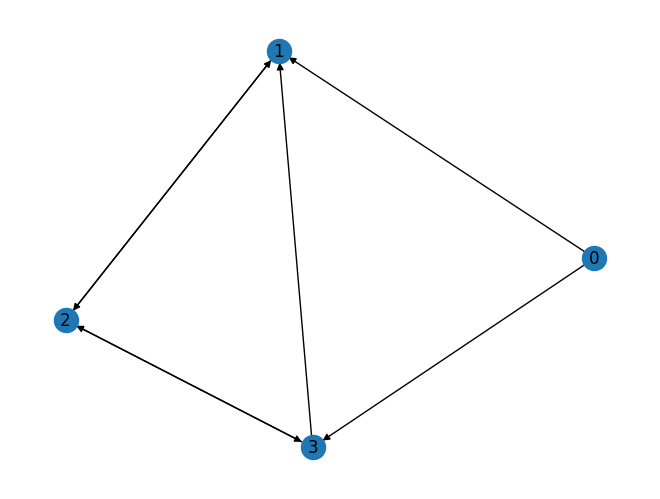

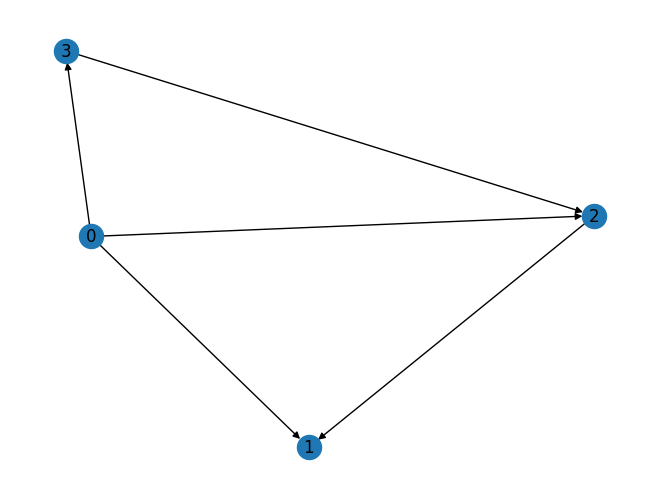

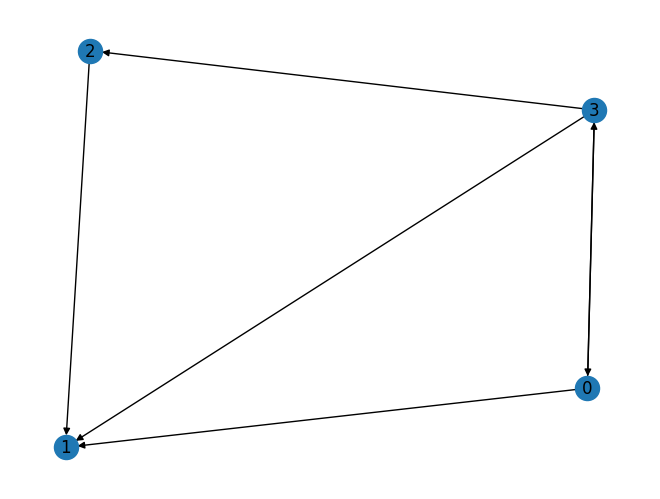

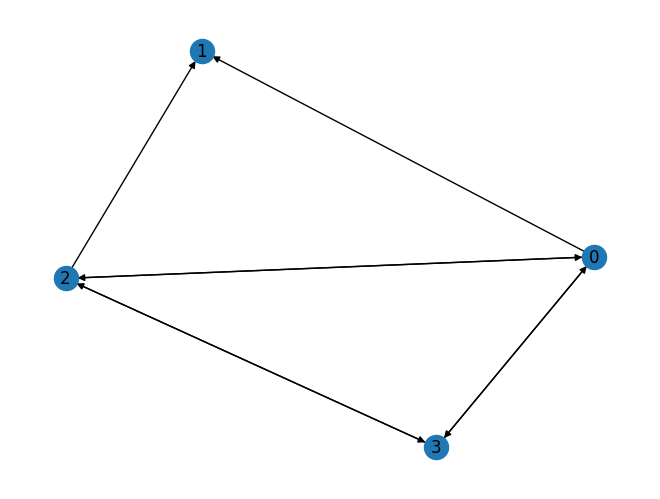

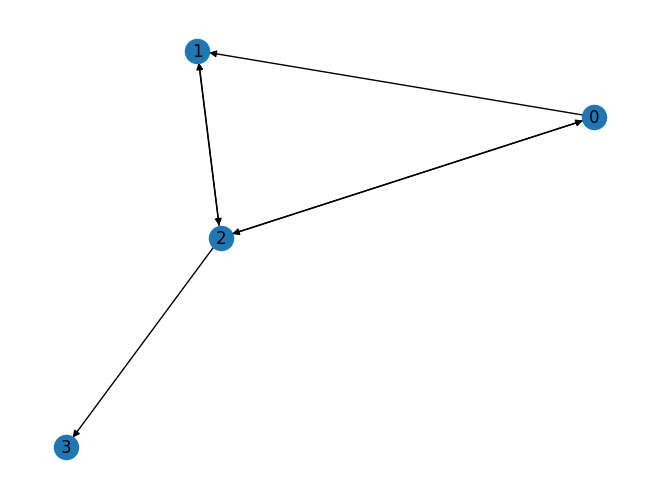

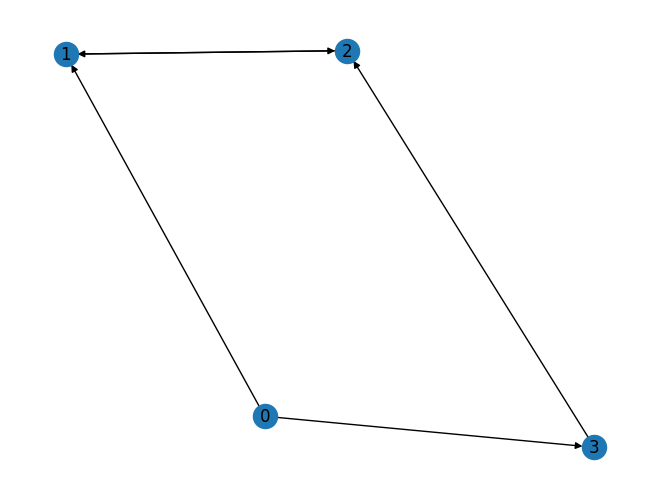

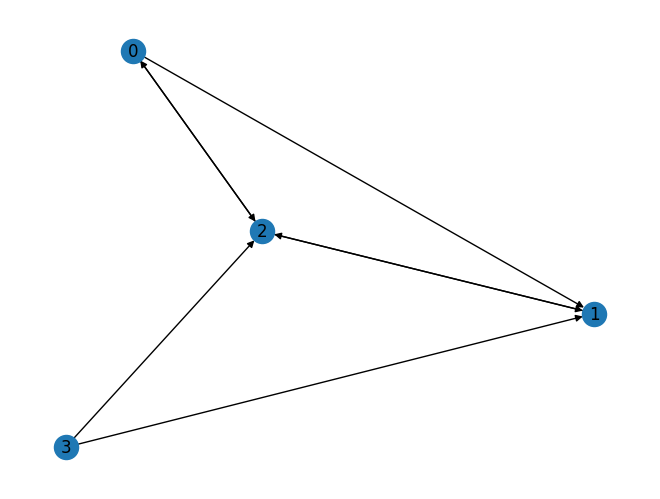

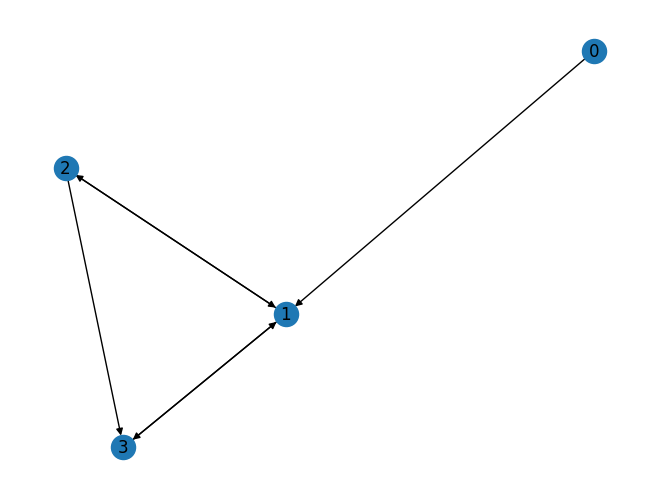

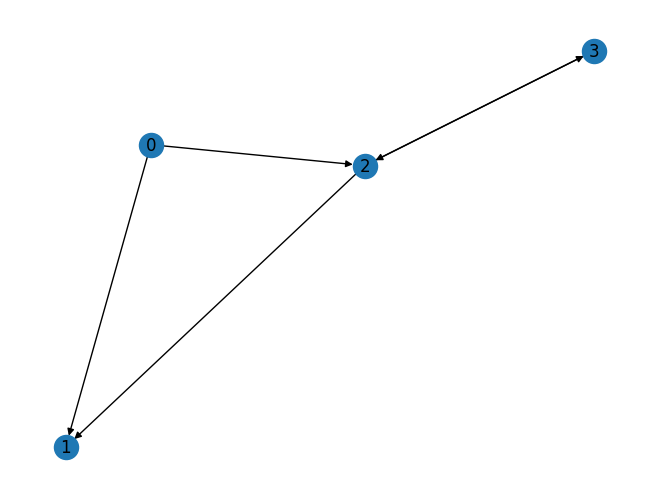

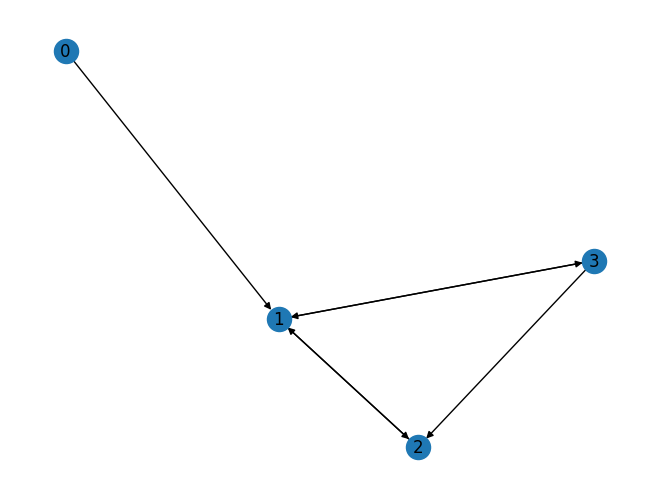

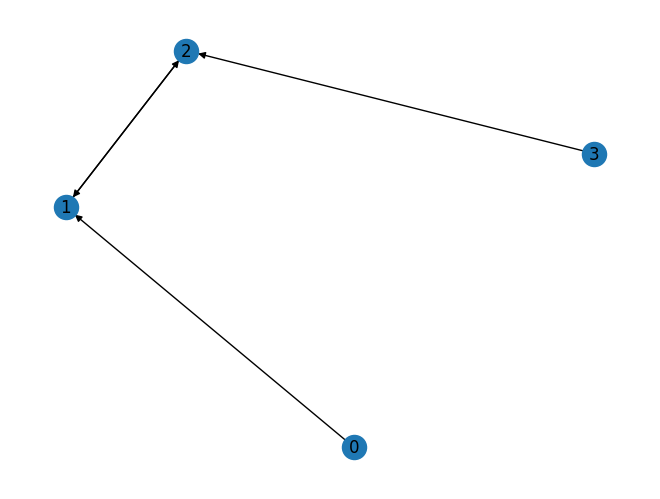

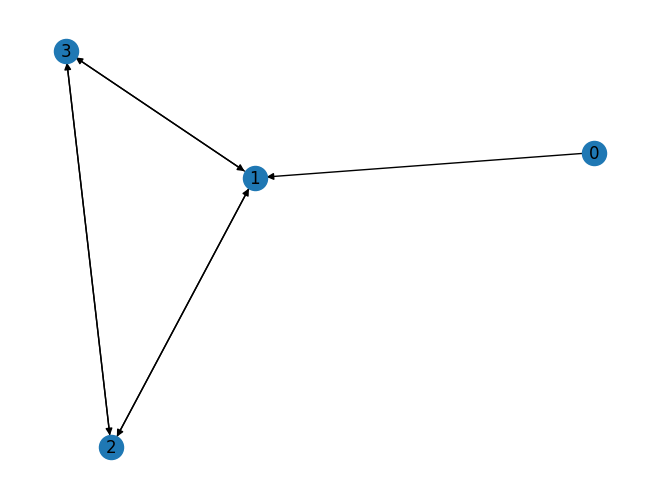

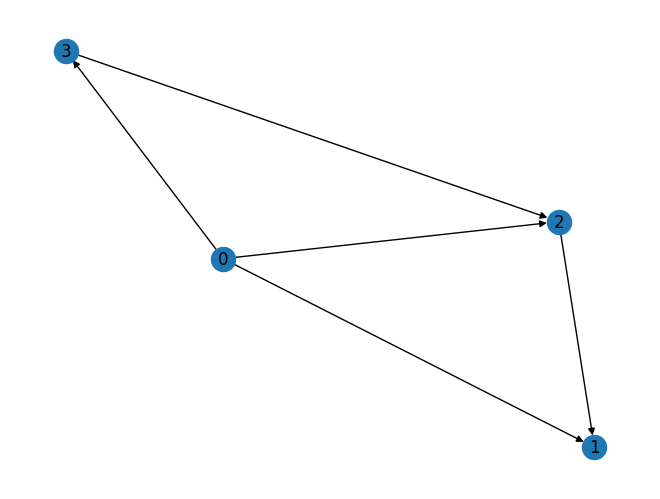

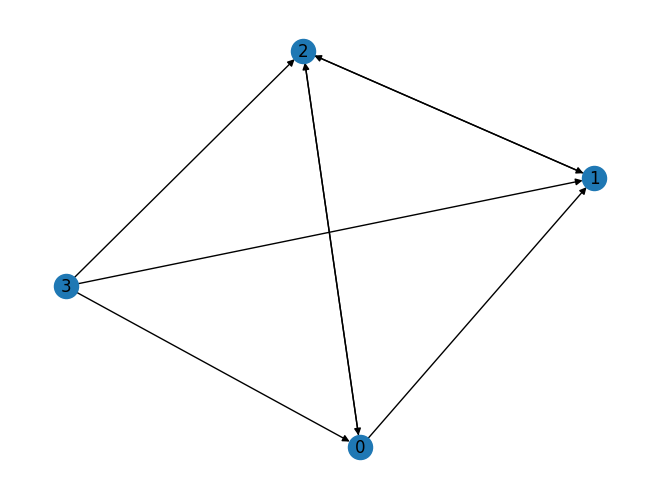

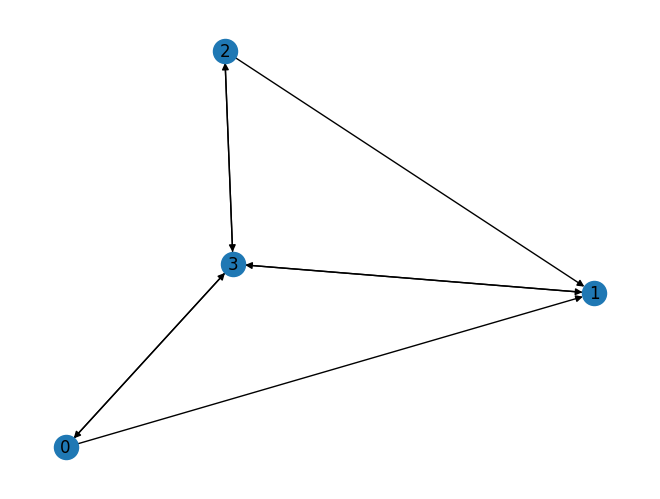

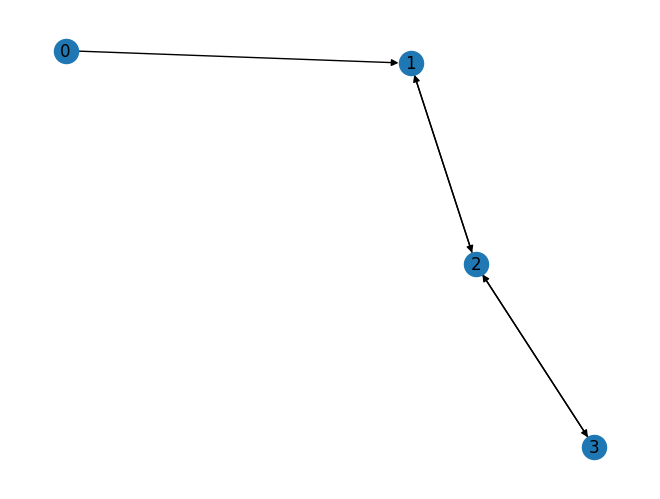

In [9]:
# Sample from the resulting posterior and draw the MAGs
mag = gfn.sample(MAG(num_nodes, batch_size=batch_size, log_reward=log_reward))

# Sort by log_reward
log_rewards = mag.log_reward()
indices = torch.argsort(log_rewards, dim=-1, descending=True)
adjacency_matrices = mag.adjacency_matrix[indices]

# Plot the MAGs
for i in indices:
    graph = nx.from_numpy_array(adjacency_matrices[i].cpu().numpy(), create_using=nx.MultiDiGraph)
    nx.draw(graph, with_labels=True)
    plt.show()